# Paper figures - reproducible calculations and rendering

This notebook produces the main manuscript figures and selected visual diagnostics from the repository's canonical outputs. It connects the account tables, prepared data, documented methods and figures used to interpret the results.

The figures use the 2024 unit-level accounts, the selected mangrove-area hierarchy: GMW 2025, FRA 2025, GMW 2024, GMW 2023, then prior BCW, Gibbs/GFW non-mangrove rates and reconstructed Busch outputs for the reforestation comparison. Inputs are read from `results/` and `data/derived/`; missing data are not replaced by zero. Alternative and provisional figures are explicitly separated from the main results until scientific validation.

The final export sequence follows the manuscript order approved for this paper:

- `Figure1.png`: Global distribution of green and blue carbon wealth.
- `Figure2.png`: Economic significance of green carbon wealth.
- `Figure3.png`: Forest and marine contributions to national carbon wealth.
- `Figure4.png`: Geographic inequality in forest carbon-removal capacity erosion.
- `Figure5.png`: GCW-based climate-finance allocations and reforestation opportunities.
- `Paper_Illustration.png`: unnumbered paper illustration of GCW on land and BCW in EEZs.

With `SAVE_FIGURES = True`, these six files are written to `results/figures/`. Captions are printed below their plots.

## 0. Current data and style

In [1]:
import glob
import os
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch, Rectangle

ROOT = Path.cwd().resolve()
while not ((ROOT / "data").is_dir() and (ROOT / "code" / "scripts").is_dir()):
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Run this notebook from the repository or one of its subfolders")
    ROOT = ROOT.parent
DATA, OUT = ROOT / "data", ROOT / "results"
SUMMARY = DATA / "derived"
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
CO2_PER_C = 44 / 12

for path in [r"C:\Windows\Fonts", os.path.expandvars(r"%LOCALAPPDATA%\Microsoft\Windows\Fonts")]:
    for font in glob.glob(os.path.join(path, "*Inter*.ttf")):
        fm.fontManager.addfont(font)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Segoe UI", "DejaVu Sans"],
    "axes.titlesize": 13,
    "axes.labelsize": 11.5,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "text.color": "black",
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
})

# --- paper-wide palette ------------------------------------------------------
BG = "#FAFAF7"          # cream background
TEXT = "black"          # all figure text is black
TEXT2 = "#5F6368"    # texte secondaire : annotations
MUTED = "#4D4D4D"       # traits secondaires seulement, jamais du texte
GRID = "#D9DDD9"
EDGE_GREY = "#9E9E9E"
MISSING_COLOR, MISSING_LABEL = "#D3D3D3", "No data"
ZERO_HATCH, ZERO_EDGE = "\\\\\\\\", "#C62828"  # reported zero: denser red top-left to bottom-right hatching

FOREST_COLS = ["#ffffcc", "#addd8e", "#78c679", "#1E8E43", "#00552f"]   # vert, figures 1 et 2 du 03
OCEAN_COLS = ["#d6ecf5", "#9ecae1", "#4292c6", "#1f6eb4", "#08306b"]
GREEN, BLUE, PINK = "#1E8E43", "#1f6eb4", "#da627d"
GROUP_COLORS = {"SIDS": "tab:blue", "Developing economies": "tab:orange",
                "Developed economies": "tab:green", "LDCs": "tab:red"}
GROUP_ORDER = ["Developed economies", "Developing economies", "LDCs", "SIDS"]

SAVE_FIGURES = True
FIGURES_TO_SAVE = {"Figure1", "Figure2", "Figure3", "Figure4", "Figure5", "Paper_Illustration"}


def save(fig, name):
    if not SAVE_FIGURES or name not in FIGURES_TO_SAVE:
        print(f"[skipped] {name}")
        return
    fig.savefig(FIGURES / f"{name}.png", dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor())
    print(f"[saved] {name}.png")

In [2]:
TABLES = OUT / "tables" / "manuscript"
VALIDATION = ROOT / "data" / "outputs" / "validation"
base = pd.read_csv(TABLES / "Supplementary_country_level_accounts_2024.csv", low_memory=False)
# UNIT_CODE is the study-unit identifier; ISO3 is retained only where a validated standard code is available.
base["iso3"] = base["UNIT_CODE"]
transitions = pd.read_csv(TABLES / "Supplementary_accounting_balance_transitions.csv")

if base["iso3"].duplicated().any():
    raise ValueError("Country account must have one row per accounting unit")
for field in ("has_gcw", "has_bcw", "reported_deforestation"):
    base[field] = base[field].astype(str).str.lower().eq("true")

# Explicit aliases keep the plotting code aligned with the current
# 2024/GMW 2025/Gibbs-GFW variables rather than older comparison inputs.
base["gcw_share_of_gdp"] = base["gcw_gdp_2024_pct"]
base["forest_share"] = 100 * base["forest_share_of_ncw"]
base["reported"] = base["reported_deforestation"]
base["loss_usd"] = base["loss_value_usd2015_yr_mean"]
base["erosion_pct"] = base["erosion_pct_of_gcw"]
base["gdp"] = base["gdp_2015usd_2024"]
base["emissions_tco2"] = base["co2_emissions_tco2_2024"]
base["population"] = base["population_2024"]

counts = {
    "forest_account": int(base["has_gcw"].sum()),
    "both_accounts": int((base["has_gcw"] & base["has_bcw"]).sum()),
    "deforestation_reporters": int(base["reported"].sum()),
    "positive_capacity_loss": int((base["reported"] & base["loss_tco2_mean"].gt(0)).sum()),
}
expected = {"forest_account": 236, "both_accounts": 174,
            "deforestation_reporters": 139, "positive_capacity_loss": 105}
if counts != expected:
    raise ValueError(f"Sample counts changed: {counts} vs {expected}")
print(f"Current account: {len(base)} units | {counts}")


Current account: 267 units | {'forest_account': 236, 'both_accounts': 174, 'deforestation_reporters': 139, 'positive_capacity_loss': 105}


C:\Users\aurel\AppData\Local\Temp\ipykernel_5656\4107337983.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  base["iso3"] = base["UNIT_CODE"]
C:\Users\aurel\AppData\Local\Temp\ipykernel_5656\4107337983.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  base["gcw_share_of_gdp"] = base["gcw_gdp_2024_pct"]
C:\Users\aurel\AppData\Local\Temp\ipykernel_5656\4107337983.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider j

### Maps and rendering functions

`class_map`, `segmented_legend`, `panel` and `clean` provide consistent rendering across panels. The Robinson projection and grey boundaries are display choices and do not modify calculated values.

In [3]:
NE_TO_UNIT = {"SDS": "SSD", "SAH": "ESH", "PSX": "PSE", "HKG": "CHN", "MAC": "CHN", "TWN": "CHN",
              "CYN": "CYP", "SOL": "SOM", "ALD": "FIN", "ATC": "AUS", "IOA": "AUS"}
world = gpd.read_file("/vsizip/" + (DATA / "raw/geospatial/boundaries/ne_50m_admin_0_countries.zip").as_posix()
                      + "/ne_50m_admin_0_countries.shp")
world["iso3"] = world["ADM0_A3"].replace(NE_TO_UNIT)
world = world.dissolve("iso3", as_index=False)[["iso3", "geometry"]]
world = world.loc[world["iso3"] != "ATA"].to_crs("+proj=robin")
WORLD_BOUNDS = world.total_bounds


def segmented_legend(ax, seg_colors, ticks, title, extra=(), seg_w=1.0, gap=0.5):
    """Horizontal segmented legend.

    `seg_w`: width of each rectangle in legend units. Isolated items in `extra`,
    including `No data`, use the same width as the bar rectangles so everything stays aligned.
    The total size is controlled by `legend_box` in `class_map`.
    `gap`: space between the bar and each isolated item, in rectangle units.
    """
    bar_h, y0 = 0.45, 0.45
    for i, color in enumerate(seg_colors):
        ax.add_patch(Rectangle((i * seg_w, y0), seg_w, bar_h, facecolor=color, edgecolor="none"))
    for i in range(1, len(seg_colors)):
        ax.axvline(i * seg_w, ymin=y0 / 1.35, ymax=(y0 + bar_h) / 1.35, color="white", linewidth=0.5)
    ax.set_xticks([i * seg_w for i in range(1, len(seg_colors))])
    ax.set_xticklabels(ticks, fontsize=9.5, color=TEXT)
    ax.tick_params(axis="x", length=0, pad=1)
    x = len(seg_colors) * seg_w
    for item in extra:
        label, color, hatch = (*item, None) if len(item) == 2 else item
        x += gap * seg_w
        ax.add_patch(Rectangle((x, y0), seg_w, bar_h, facecolor=color,
                                 edgecolor=ZERO_EDGE if hatch else "none",
                                 hatch=hatch or ""))
        ax.text(x + seg_w / 2, y0 - 0.14, label, fontsize=9.5, ha="center", va="top", color=TEXT)
        x += seg_w
    ax.text(len(seg_colors) * seg_w / 2, 1.12, title, fontsize=10.5, ha="center", va="bottom", color=TEXT)
    ax.set_xlim(0, x + 0.05 * seg_w)
    ax.set_ylim(0, 1.35)
    ax.set_yticks([])
    ax.set_facecolor("none")
    for spine in ax.spines.values():
        spine.set_visible(False)


def class_map(ax, values, bins, ticks, colors, legend_title, extra_cats=None,
              legend_box=(0.20, -0.16, 0.60, 0.13), legend_seg_w=1.0, legend_gap=0.5):
    """Classified map. `extra_cats` is a list of (boolean mask indexed by iso3, label, colour).

    `legend_box` fixes the position and total size of the legend in map-axes coordinates;
    `legend_seg_w` and `legend_gap` are passed to `segmented_legend`.
    """
    data = world.merge(values.rename("value"), left_on="iso3", right_index=True, how="left")
    data["_cls"] = pd.cut(data["value"], bins=bins, labels=False)
    painted = data["_cls"].notna()
    extra = []
    for item in (extra_cats or []):
        mask, label, color, hatch = (*item, None) if len(item) == 3 else item
        sel = data["iso3"].map(mask).fillna(False) & ~painted
        if sel.any():
            data.loc[sel].plot(ax=ax, color=MISSING_COLOR if hatch else color,
                              edgecolor=ZERO_EDGE if hatch else EDGE_GREY,
                              linewidth=0.2, hatch=hatch)
        painted = painted | sel
        extra.append((label, MISSING_COLOR if hatch else color, hatch))
    rest = data.loc[~painted]
    if not rest.empty:
        rest.plot(ax=ax, color=MISSING_COLOR, edgecolor=EDGE_GREY, linewidth=0.2)
        extra.append((MISSING_LABEL, MISSING_COLOR))
    for i, color in enumerate(colors):
        subset = data.loc[data["_cls"] == i]
        if not subset.empty:
            subset.plot(ax=ax, color=color, edgecolor=EDGE_GREY, linewidth=0.2)
    ax.set_xlim(WORLD_BOUNDS[0], WORLD_BOUNDS[2])
    ax.set_ylim(WORLD_BOUNDS[1], WORLD_BOUNDS[3])
    ax.set_aspect("equal")
    ax.axis("off")
    segmented_legend(ax.inset_axes(list(legend_box)), colors, ticks, legend_title, extra,
                     seg_w=legend_seg_w, gap=legend_gap)


# Bold panel letters. The installed Inter font is variable: matplotlib exposes weight 400
# under the name `Inter`, while the bold face is available as `Inter 18pt` (weight 700).
# The letter is written with mathtext; chr(92) avoids a backslash in the source string.
plt.rcParams.update({"mathtext.fontset": "custom", "mathtext.rm": "Inter",
                     "mathtext.bf": "Inter 18pt:bold", "mathtext.it": "Inter:italic"})
BOLD = chr(92) + "mathbf"


def panel(ax, letter, title, loc="left", pad=9):
    """Display only the panel letter; titles are printed in the captions."""
    if letter:
        ax.set_title(f"${BOLD}{{{letter}}}$", loc=loc, fontsize=12.5, color=TEXT, pad=pad)


def clean(ax, grid_axis="y", spines=()):
    """Cream background, no spines except those requested, optional light grid."""
    ax.set_facecolor(BG)
    for side, spine in ax.spines.items():
        spine.set_visible(side in spines)
        if side in spines:
            spine.set_color("black")
            spine.set_linewidth(0.9)
    ax.tick_params(length=3 if spines else 0, colors="black", labelsize=10)
    if grid_axis:
        ax.grid(axis=grid_axis, color=GRID, linewidth=0.7, zorder=0)
        ax.set_axisbelow(True)
    else:
        ax.grid(False)

## Forest carbon value relative to GDP

The map uses the current account table and the paper's forest palette. The denominator is 2024 GDP. Reported zeros and missing observations are kept distinct.

**Origin of the three zero values.** Monaco and Nauru have zero 2025 forest area in FRA. Kiribati reports 1,070 ha of forest, but its report classifies that area as mangrove; those hectares are removed from the forest account under the selected rule. Kiribati is therefore zero because of this documented exclusion, not because FRA reports zero forest area. The three zero GCW/GDP values come from these source values or documented subtractions, not from a general missing-to-zero replacement. Gibbs/GFW rates are positive.

[saved] Figure2.png


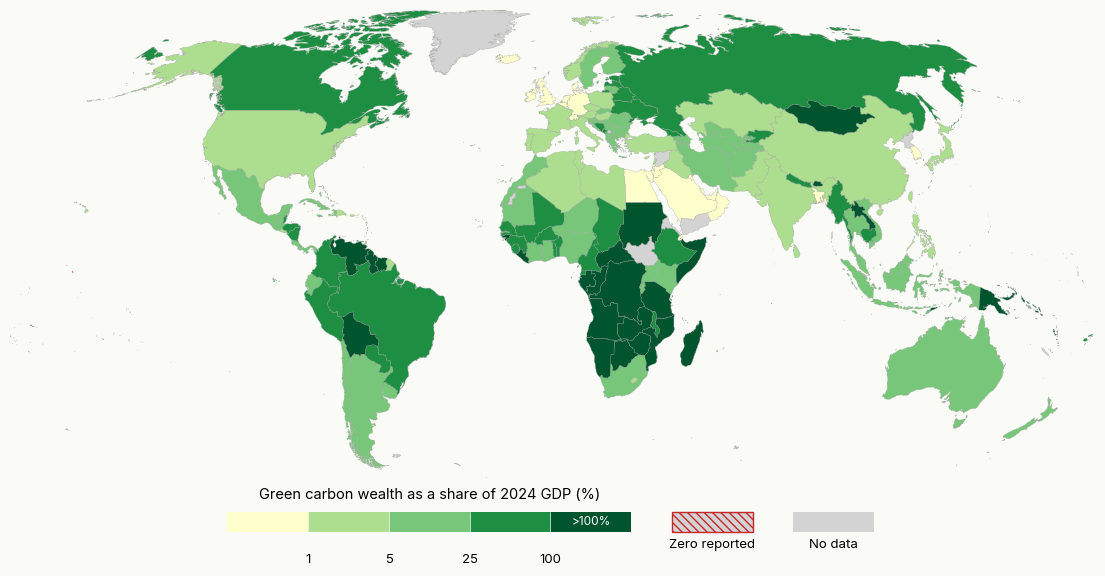

Figure 2 caption:
Fig. 2: Economic significance of green carbon wealth. The map shows national GCW as a share of 2024 GDP; reported zeros and unavailable observations are shown separately.


In [4]:
# Figure 2: Economic significance of green carbon wealth.
fig = plt.figure(figsize=(14, 6.6), facecolor=BG)

# (a) GCW / GDP map
ax = fig.add_subplot(111)
ax.set_facecolor(BG)
zero_gcw_gdp = base.set_index("iso3")["gcw_share_of_gdp"].eq(0)
class_map(ax, base.set_index("iso3")["gcw_share_of_gdp"],
          bins=[0, 1, 5, 25, 100, np.inf], ticks=["1", "5", "25", "100"],
          colors=FOREST_COLS, legend_title="Green carbon wealth as a share of 2024 GDP (%)",
          extra_cats=[(zero_gcw_gdp, "Zero reported", MISSING_COLOR, ZERO_HATCH)])
ax.child_axes[-1].text(4.5, 0.68, ">100%", ha="center", va="center", fontsize=8.5, color="white")
panel(ax, "", "Forest carbon value relative to the size of the economy", loc="center")


save(fig, "Figure2")
plt.show()
print("Figure 2 caption:\nFig. 2: Economic significance of green carbon wealth. The map shows national GCW as a share of 2024 GDP; reported zeros and unavailable observations are shown separately.")


### Alternative presentation - three-panel composition

This alternative places the map, global cascade and Lorenz curves side by side using the same current tables as the main figure. Amounts come from Table 1 and the map uses 2024 GDP. It is retained only to compare presentation choices before the manuscript layout is selected.

<>:45: SyntaxWarning: invalid escape sequence '\$'
<>:45: SyntaxWarning: invalid escape sequence '\$'
C:\Users\aurel\AppData\Local\Temp\ipykernel_5656\271226126.py:45: SyntaxWarning: invalid escape sequence '\$'
  ax.set_ylabel("Trillion 2015 US\$ per year", fontsize=11)


[skipped] Alternative_original_Figure1_three_panels_2024


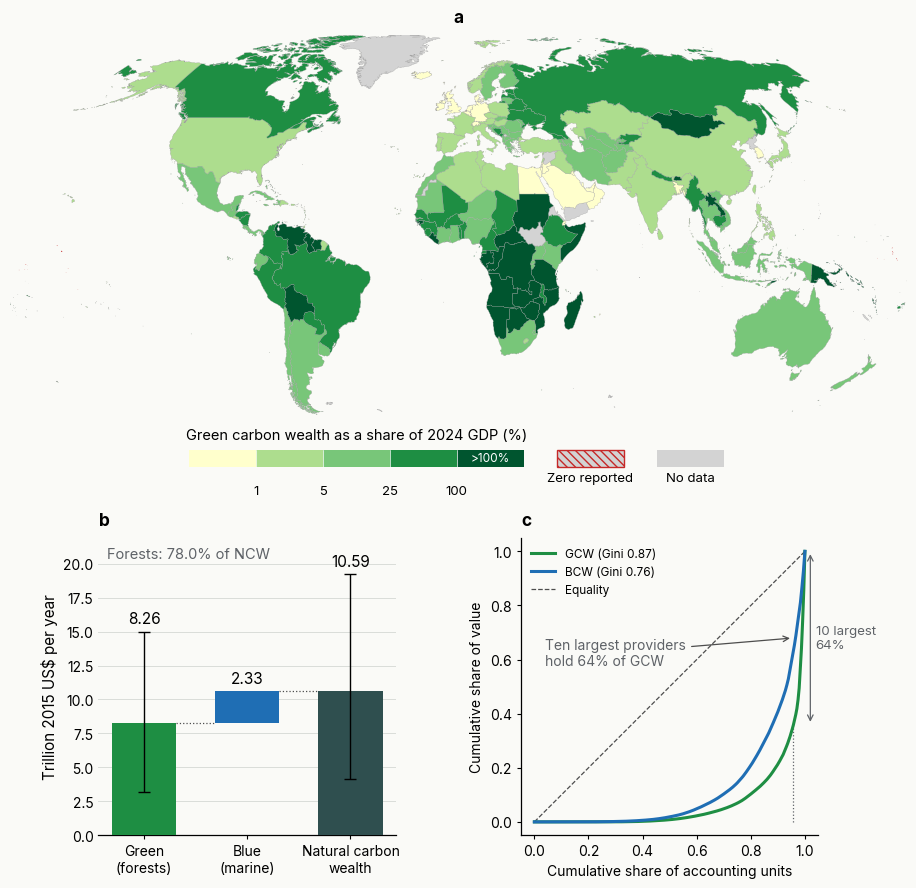

Alternative Figure 1 caption:
Fig. 1: National carbon wealth and its concentration. a. Forest carbon value relative to 2024 GDP. b. Global annual value of the carbon service. c. Concentration of GCW and BCW across accounting units.


In [5]:
fig = plt.figure(figsize=(14, 10.4), facecolor=BG)
grid = fig.add_gridspec(2, 2, height_ratios=[1.30, 1], hspace=0.34, wspace=0.26)

# (a) GCW / GDP map
ax = fig.add_subplot(grid[0, :])
ax.set_facecolor(BG)
zero_gcw_gdp = base.set_index("iso3")["gcw_share_of_gdp"].eq(0)
class_map(ax, base.set_index("iso3")["gcw_share_of_gdp"],
          bins=[0, 1, 5, 25, 100, np.inf], ticks=["1", "5", "25", "100"],
          colors=FOREST_COLS, legend_title="Green carbon wealth as a share of 2024 GDP (%)",
          extra_cats=[(zero_gcw_gdp, "Zero reported", MISSING_COLOR, ZERO_HATCH)])
ax.child_axes[-1].text(4.5, 0.68, ">100%", ha="center", va="center", fontsize=8.5, color="white")
panel(ax, "a", "Forest carbon value relative to the size of the economy", loc="center")

# (b) cascade GCW -> BCW -> NCW
ax = fig.add_subplot(grid[1, 0])
clean(ax, spines=("bottom"))
ax.set_box_aspect(1)
ax.set_anchor("E")          # move the two square panels towards the figure centre
global_account = pd.read_csv(TABLES / "Table1_global_carbon_wealth.csv")
global_account = global_account.set_index("component")
names = ["Green carbon wealth", "Blue carbon wealth", "Natural carbon wealth"]
means = global_account.loc[names, "value_mean_trillion_usd2015_yr"].to_numpy()
lo = global_account.loc[names, "value_p05_trillion_usd2015_yr"].to_numpy()
hi = global_account.loc[names, "value_p95_trillion_usd2015_yr"].to_numpy()
xs = np.arange(3)
ax.bar(xs[0], means[0], 0.62, color=GREEN, zorder=3)
ax.bar(xs[1], means[1], 0.62, bottom=means[0], color=BLUE, zorder=3)
ax.bar(xs[2], means[2], 0.62, color="#2f4f4f", zorder=3)
ax.plot([0.31, 0.69], [means[0]] * 2, color=MUTED, lw=0.9, ls=":", zorder=4)
ax.plot([1.31, 1.69], [means[2]] * 2, color=MUTED, lw=0.9, ls=":", zorder=4)
for i, (m, l, h) in enumerate(zip(means, lo, hi)):
    if i == 1:
        # blue is stacked on green, so its value is written above the stack
        label_y = means[0] + m
    else:
        ax.errorbar(xs[i], m, yerr=[[m - l], [h - m]], fmt="none", ecolor=TEXT,
                    elinewidth=1.0, capsize=4, zorder=5)
        label_y = h                      # above the whisker, never across it
    ax.text(xs[i], label_y + max(hi) * 0.02, f"{m:.2f}", ha="center", va="bottom", fontsize=11,
            fontweight="bold", color=TEXT)
ax.set_xticks(xs)
ax.tick_params(axis="y", which="both", length=0)
ax.set_xticklabels(["Green\n(forests)", "Blue\n(marine)", "Natural carbon\nwealth"], fontsize=10)
ax.set_ylabel("Trillion 2015 US\$ per year", fontsize=11)
ax.set_ylim(0, max(hi) * 1.14)
ax.text(0.03, 0.97, f"Forests: {100 * means[0] / means[2]:.1f}% of NCW", transform=ax.transAxes,
        fontsize=10.5, va="top", color=TEXT2)
panel(ax, "b", "Global annual value of the carbon service")

# (c) Lorenz
ax = fig.add_subplot(grid[1, 1])
clean(ax, grid_axis=None, spines=("left", "bottom"))
ax.set_box_aspect(1)
ax.set_anchor("W")


def lorenz(values):
    v = np.sort(np.asarray(values, dtype="float64"))
    v = v[~np.isnan(v)]
    return np.linspace(0, 1, v.size + 1), np.concatenate([[0], np.cumsum(v) / v.sum()])


def gini(values):
    v = np.sort(np.asarray(values, dtype="float64"))
    v = v[~np.isnan(v)]
    k = v.size
    return float((2 * np.arange(1, k + 1) - k - 1) @ v / (k * v.sum()))



for col, color, label in [("gcw_usd2015_yr_mean", GREEN, "GCW"),
                          ("bcw_usd2015_yr_mean", BLUE, "BCW")]:
    x, y = lorenz(base[col])
    ax.plot(x, y, color=color, lw=2.2, label=f"{label} (Gini {gini(base[col]):.2f})", zorder=3)
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=0.9, label="Equality", zorder=2)
top10 = base.nlargest(10, "gcw_usd2015_yr_mean")["gcw_usd2015_yr_mean"].sum() / base["gcw_usd2015_yr_mean"].sum()
ax.annotate(f"Ten largest providers\nhold {100 * top10:.0f}% of GCW", xy=(0.955, 1 - top10 / 2),
            xytext=(0.04, 0.58), fontsize=10, color=TEXT2,
            arrowprops=dict(arrowstyle="->", color=MUTED, lw=0.9))
ax.set_xlabel("Cumulative share of accounting units", fontsize=10)
ax.set_ylabel("Cumulative share of value", fontsize=10)
ax.legend(frameon=False, loc="upper left", fontsize=8.5)
x_cut = 1 - 10 / base["gcw_usd2015_yr_mean"].notna().sum()   # ≈ 0,96
y_cut = 1 - top10                                            # ≈ 0,43
ax.plot([x_cut, x_cut], [0, y_cut], color=TEXT2, ls=":", lw=0.9)
ax.annotate("", xy=(1.02, 1.0), xytext=(1.02, y_cut),
            arrowprops=dict(arrowstyle="<->", color=TEXT2, lw=0.9), annotation_clip=False)
ax.text(1.04, (1 + y_cut) / 2, f"10 largest\n{100 * top10:.0f}%", va="center", fontsize=9.5,
        color=TEXT2, transform=ax.transData, clip_on=False)
panel(ax, "c", "Concentration across countries")

save(fig, "Alternative_original_Figure1_three_panels_2024")
plt.show()
print("Alternative Figure 1 caption:\nFig. 1: National carbon wealth and its concentration. a. Forest carbon value relative to 2024 GDP. b. Global annual value of the carbon service. c. Concentration of GCW and BCW across accounting units.")

## Green and blue wealth composition

The colour gradient represents GCW / (GCW + BCW) only where both accounts are available. Units with GCW but no BCW are identified separately as **GCW only**: their forest value exists, but their share of total carbon wealth cannot be calculated. Units with BCW but no GCW are placed in the 0-20% class under the selected map convention. **No data** identifies units without a usable account for this map. Missing BCW and NCW values remain missing in the data; the display does not impute a zero. The accounting-transition diagram is shown separately.

GCW only with BCW unavailable: 62 units; map audit written


[saved] Figure3.png


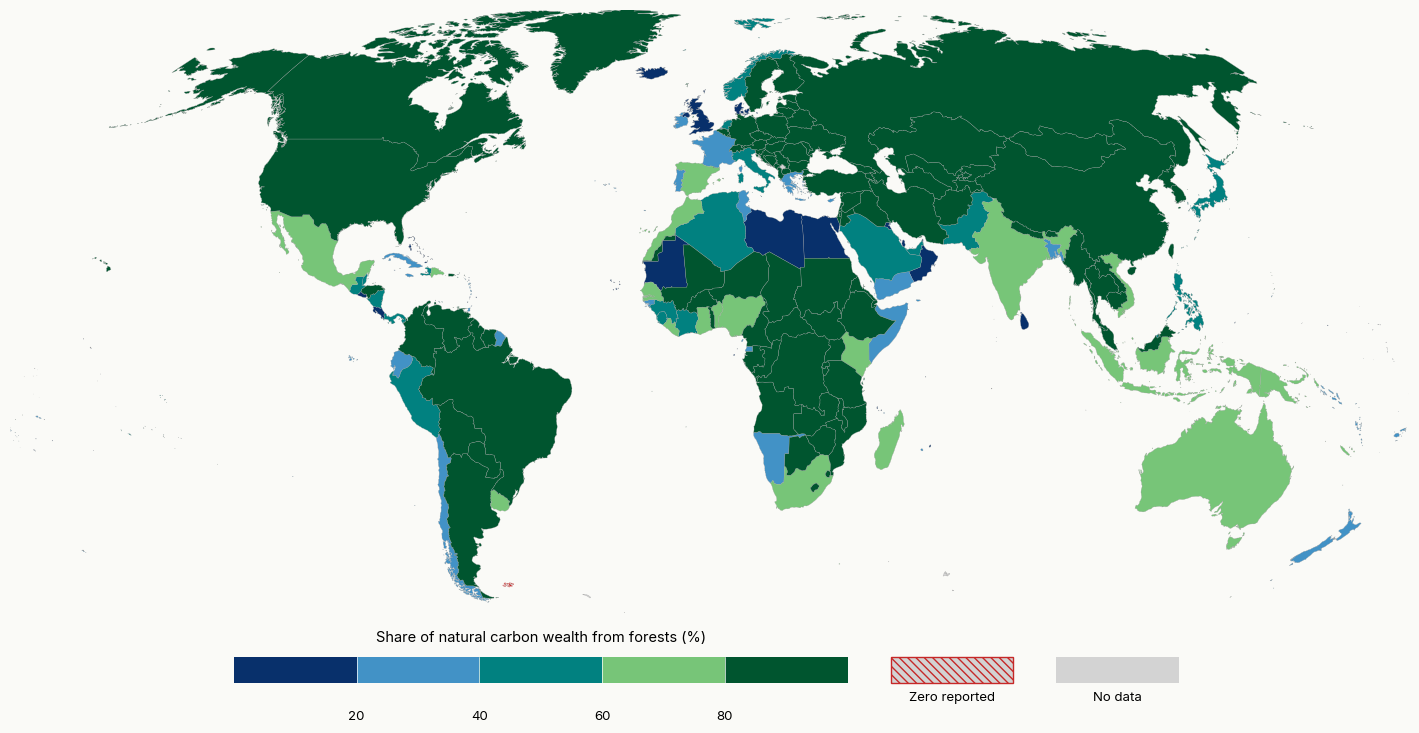

Figure 3 caption:
Fig. 3: Forest and marine contributions to national carbon wealth. The map shows the forest share of GCW plus BCW; an unavailable component is set to zero only inside this figure ratio, while source availability remains unchanged.


In [6]:
# Figure 3: Forest and marine contributions to national carbon wealth.
GREEN_BLUE = LinearSegmentedColormap.from_list(
    "gb", [OCEAN_COLS[4], OCEAN_COLS[2], "#008080", FOREST_COLS[2], FOREST_COLS[4]]
)
COMP_COLORS = [GREEN_BLUE(t) for t in np.linspace(0, 1, 5)]

fig, ax = plt.subplots(figsize=(15.5, 8.5), facecolor=BG)
fig.subplots_adjust(left=0.035, right=0.965, top=0.90, bottom=0.19)
ax.set_facecolor(BG)
indexed = base.set_index("iso3")
gcw_only = indexed["has_gcw"] & ~indexed["has_bcw"]
bcw_only = ~indexed["has_gcw"] & indexed["has_bcw"]
# Figure-only rule: missing GCW/BCW values act as zero in the ratio; source data remain missing.
gcw_plot = indexed["gcw_usd2015_yr_mean"].fillna(0.0)
bcw_plot = indexed["bcw_usd2015_yr_mean"].fillna(0.0)
plot_total = gcw_plot + bcw_plot
composition_share_plot = (100 * gcw_plot / plot_total).where(plot_total.gt(0))
zero_composition = ((indexed["has_gcw"] & indexed["gcw_usd2015_yr_mean"].eq(0)) |
                    (indexed["has_bcw"] & indexed["bcw_usd2015_yr_mean"].eq(0)))
if int(gcw_only.sum()) != 62 or int(bcw_only.sum()) != 6:
    raise ValueError("Figure 2 account-availability classification no longer matches the account data")
# Keep the map's account availability classification in an auditable table.
map_audit = base[["UNIT_CODE", "name", "has_gcw", "has_bcw",
                  "gcw_usd2015_yr_mean", "bcw_usd2015_yr_mean",
                  "forest_share_of_ncw"]].copy()
map_audit["composition_map_status"] = np.select(
    [map_audit.has_gcw & map_audit.has_bcw,
     map_audit.has_gcw & ~map_audit.has_bcw,
     ~map_audit.has_gcw & map_audit.has_bcw],
    ["GCW and BCW", "GCW only; BCW unavailable", "BCW only; GCW unavailable"],
    default="No account",
)
expected_status = {"GCW and BCW": 174, "GCW only; BCW unavailable": 62,
                   "BCW only; GCW unavailable": 6, "No account": 24}
if map_audit.composition_map_status.value_counts().to_dict() != expected_status:
    raise ValueError("Figure 2 account-availability counts changed")
map_audit.to_csv(TABLES / "Supplementary_Figure2_map_categories.csv", index=False)
print(f"GCW only with BCW unavailable: {int(gcw_only.sum())} units; map audit written")
class_map(
    ax, composition_share_plot,
    bins=[-np.inf, 20, 40, 60, 80, np.inf], ticks=["20", "40", "60", "80"],
    colors=COMP_COLORS, legend_title="Share of natural carbon wealth from forests (%)",
    extra_cats=[(zero_composition, "Zero reported", MISSING_COLOR, ZERO_HATCH)],
    legend_box=(0.16, -0.16, 0.68, 0.13), legend_gap=0.35,
)
panel(ax, "", "Blue and green composition of national carbon wealth", loc="center", pad=16)

save(fig, "Figure3")
plt.show()
print("Figure 3 caption:\nFig. 3: Forest and marine contributions to national carbon wealth. The map shows the forest share of GCW plus BCW; an unavailable component is set to zero only inside this figure ratio, while source availability remains unchanged.")

### Supplementary diagnostic - accounting-balance transitions

This standalone diagram shows the 161 study units with both carbon accounts and 2024 emissions. It tracks how many units move between positive and non-positive accounting balances when the marine account is added. The labels describe the account definitions and counts; they are not panel letters.

[skipped] Candidate_accounting_balance_transitions


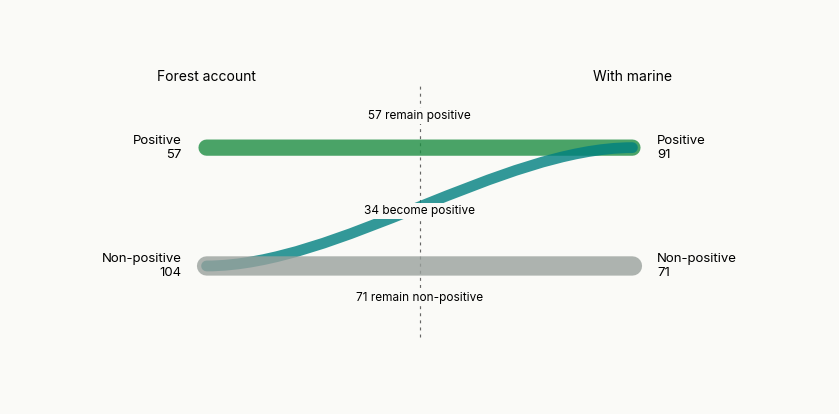

Supplementary accounting-transition caption:
Accounting-balance transitions after adding the marine account (n=161). The flows show units remaining positive, becoming positive, or remaining non-positive after the marine component is added.


In [7]:
# Counts use the common 161-unit sample and are checked against the current account table.
matrix = transitions.set_index(
    ["before_gcw_balance_positive", "after_ncw_balance_positive"]
)["units"]
stayed_positive = int(matrix.loc[(True, True)])
became_positive = int(matrix.loc[(False, True)])
stayed_nonpositive = int(matrix.loc[(False, False)])
became_nonpositive = int(matrix.loc[(True, False)])
n = int(transitions["common_sample_n"].iloc[0])
if (n, stayed_positive, became_positive, stayed_nonpositive, became_nonpositive) != (161, 57, 34, 70, 0):
    raise ValueError("The 2024 accounting-balance transition counts changed")

from matplotlib.path import Path as MplPath
from matplotlib.patches import PathPatch

fig, ax = plt.subplots(figsize=(10.5, 5.8), facecolor=BG)
fig.subplots_adjust(left=0.11, right=0.89, top=0.80, bottom=0.12)
clean(ax, grid_axis=None)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
# The dotted divider separates the before and after account columns.
ax.plot([0.50, 0.50], [0.17, 0.81], color=MUTED, lw=0.85,
        ls=(0, (2.5, 3.5)), alpha=0.85, zorder=1)

def connect(y0, y1, count, color):
    curve = MplPath(
        [(0.24, y0), (0.40, y0), (0.60, y1), (0.76, y1)],
        [MplPath.MOVETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4],
    )
    ax.add_patch(PathPatch(curve, fill=False, edgecolor=color, linewidth=2 + 0.17 * count,
                           alpha=0.80, capstyle="round", zorder=2))

connect(0.65, 0.65, stayed_positive, GREEN)
connect(0.35, 0.65, became_positive, "#008080")
connect(0.35, 0.35, stayed_nonpositive, "#9AA19D")
ax.text(0.24, 0.83, "Forest account", ha="center", va="center", fontsize=10, color=TEXT)
ax.text(0.76, 0.83, "With marine", ha="center", va="center", fontsize=10, color=TEXT)
ax.text(0.21, 0.65, "Positive\n57", ha="right", va="center", fontsize=9.5, color=TEXT)
ax.text(0.21, 0.35, "Non-positive\n104", ha="right", va="center", fontsize=9.5, color=TEXT)
ax.text(0.79, 0.65, "Positive\n91", ha="left", va="center", fontsize=9.5, color=TEXT)
ax.text(0.79, 0.35, "Non-positive\n71", ha="left", va="center", fontsize=9.5, color=TEXT)
for x, y, label in [
    (0.50, 0.73, "57 remain positive"),
    (0.50, 0.49, "34 become positive"),
    (0.50, 0.27, "71 remain non-positive"),
]:
    ax.text(x, y, label, ha="center", va="center", fontsize=8.5, color=TEXT,
            bbox={"facecolor": BG, "edgecolor": "none", "pad": 1.3}, zorder=4)
panel(ax, "", "Accounting-balance transitions after adding the marine account (n=161)",
      loc="center", pad=16)

save(fig, "Candidate_accounting_balance_transitions")
plt.show()
print("Supplementary accounting-transition caption:\nAccounting-balance transitions after adding the marine account (n=161). The flows show units remaining positive, becoming positive, or remaining non-positive after the marine component is added.")

### Alternative presentation - three-panel composition

This alternative places the map, unit-level flows and accounting-balance cloud side by side using the 2024 accounts. The separately displayed transition panel provides another reading of the same observations.

[skipped] Alternative_original_Figure2_three_panels_2024


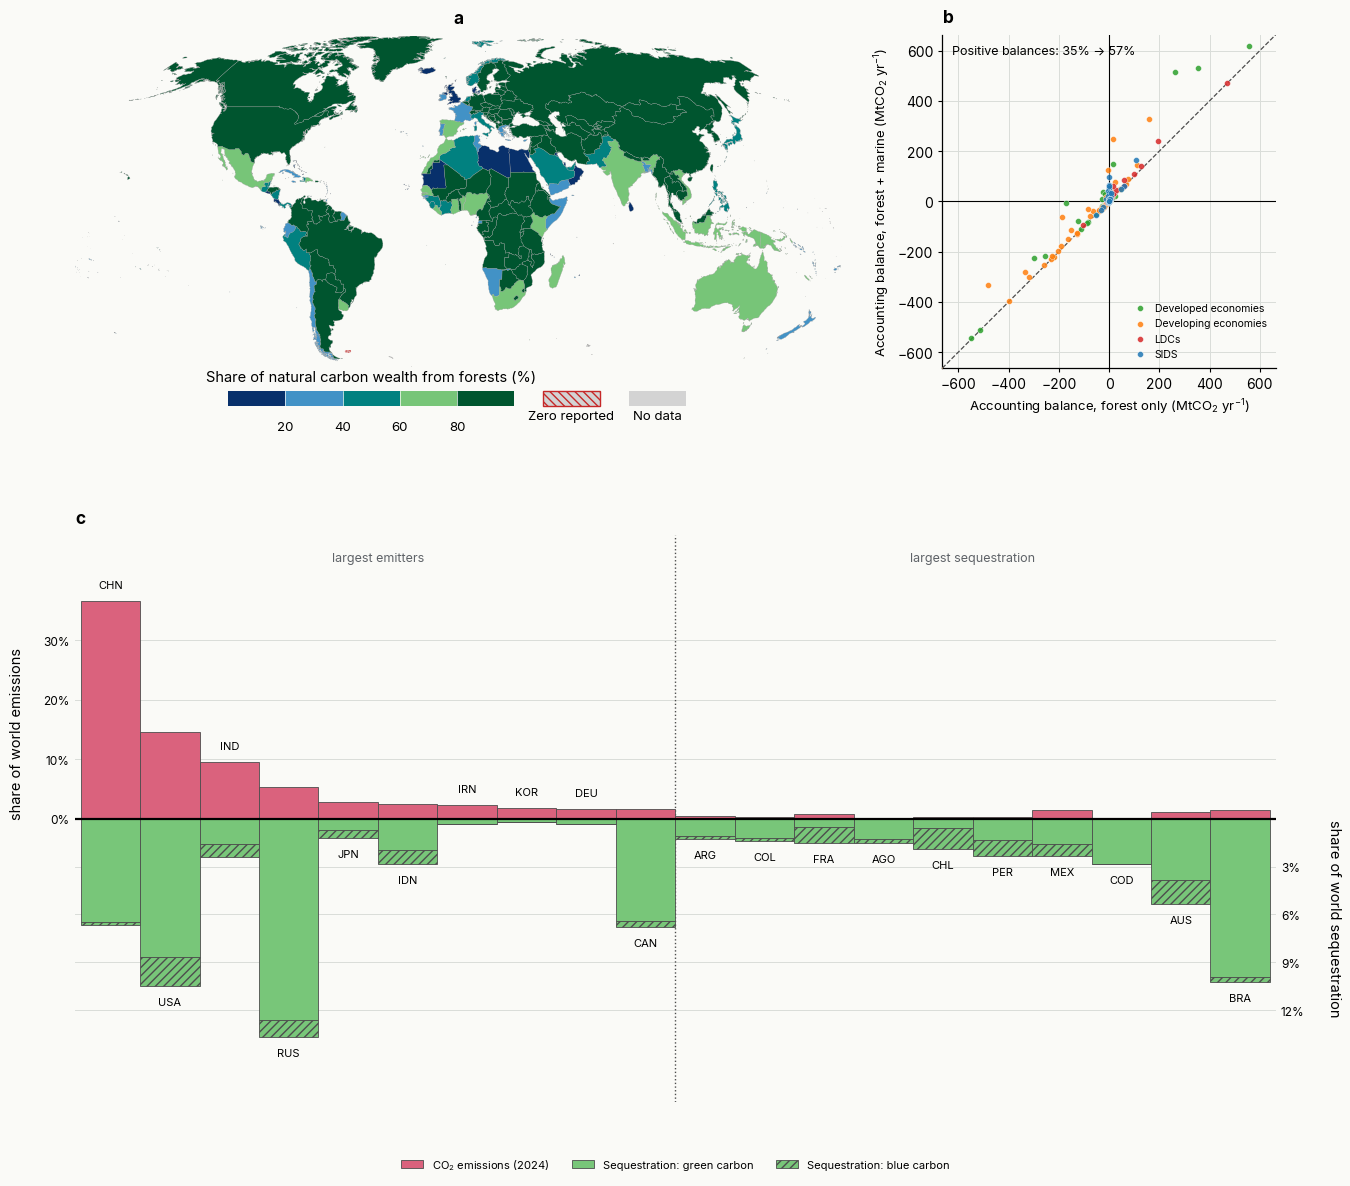

Alternative Figure 2 caption:
Fig. 2: Marine additions change the composition and accounting balance of national carbon wealth. a. Forest share of combined natural carbon wealth. b. Forest-only versus forest-plus-marine accounting balances. c. Countries with the largest emissions and accounted sequestration contributions. Marine flux is current coastal uptake, including mangroves valued with GMW 2025 area, plus the open-ocean BCP flux retained from the source account.


In [8]:
GREEN_BLUE = LinearSegmentedColormap.from_list("gb", [OCEAN_COLS[4], OCEAN_COLS[2], "#008080",
                                                      FOREST_COLS[2], FOREST_COLS[4]])
COMP_COLORS = [GREEN_BLUE(t) for t in np.linspace(0, 1, 5)]

balance = base.loc[base["has_gcw"] & base["has_bcw"], ["iso3", "groups", "gcw_accounting_balance_mean_tco2_yr", "ncw_accounting_balance_mean_tco2_yr"]].rename(columns={"gcw_accounting_balance_mean_tco2_yr": "bal_gcw", "ncw_accounting_balance_mean_tco2_yr": "bal_ncw"}).dropna()
if len(balance) != 161:
    raise ValueError(f"Expected 161 units with both accounts and emissions, got {len(balance)}")
sink_before = 100 * (balance["bal_gcw"] > 0).mean()
sink_after = 100 * (balance["bal_ncw"] > 0).mean()

fig = plt.figure(figsize=(15.5, 14), facecolor=BG)
grid = fig.add_gridspec(2, 3, height_ratios=[1.25, 2], hspace=0.34, wspace=0.30)

# (a) account-composition map
ax = fig.add_subplot(grid[0, 0:2])
ax.set_facecolor(BG)
indexed = base.set_index("iso3")
gcw_plot = indexed["gcw_usd2015_yr_mean"].fillna(0.0)
bcw_plot = indexed["bcw_usd2015_yr_mean"].fillna(0.0)
plot_total = gcw_plot + bcw_plot
composition_share_plot = (100 * gcw_plot / plot_total).where(plot_total.gt(0))
zero_composition = ((indexed["has_gcw"] & indexed["gcw_usd2015_yr_mean"].eq(0)) |
                    (indexed["has_bcw"] & indexed["bcw_usd2015_yr_mean"].eq(0)))
class_map(ax, composition_share_plot,
          bins=[-np.inf, 20, 40, 60, 80, np.inf], ticks=["20", "40", "60", "80"],
          colors=COMP_COLORS, legend_title="Share of natural carbon wealth from forests (%)",
          extra_cats=[(zero_composition, "Zero reported", MISSING_COLOR, ZERO_HATCH)])
panel(ax, "a", "Blue and green composition of national carbon wealth", loc="center")

# (c) emissions upward, sequestration downward - lower full-width band
ax = fig.add_subplot(grid[1, :])
clean(ax, grid_axis=None)

panel_src = base.rename(columns={
    "coastal_component_uptake_tC_yr_current_area": "coastal_flux_tC_yr_actual",
    "open_ocean_bcp_tC_yr_source": "open_ocean_bcp_flux_tC_yr_source",
}).dropna(subset=["emissions_tco2", "population"]).copy()
panel_src["seq_gcw"] = panel_src["gcw_additions_tco2_yr"]
panel_src["total_bcw_flux_tC_yr_actual"] = (
    panel_src["coastal_flux_tC_yr_actual"] + panel_src["open_ocean_bcp_flux_tC_yr_source"]
)
panel_src["seq_bcw"] = panel_src["total_bcw_flux_tC_yr_actual"] * (44 / 12)
panel_src = panel_src.dropna(subset=["seq_gcw", "seq_bcw"])
panel_src["seq_total"] = panel_src["seq_gcw"] + panel_src["seq_bcw"]
left = panel_src.nlargest(10, "emissions_tco2").sort_values("emissions_tco2", ascending=False)
right = (panel_src[~panel_src["iso3"].isin(left["iso3"])].nlargest(10, "seq_total")
         .sort_values("seq_total"))
pan = pd.concat([left, right], ignore_index=True)

world_emis, world_seq = panel_src["emissions_tco2"].sum(), panel_src["seq_total"].sum()
e = 100 * pan["emissions_tco2"].to_numpy() / world_emis
g_ = 100 * pan["seq_gcw"].to_numpy() / world_seq
b_ = 100 * pan["seq_bcw"].to_numpy() / world_seq
k = e.max() / (g_ + b_).max()
x = np.arange(len(pan))
bar = dict(width=1.0, edgecolor="#4d4d4d", linewidth=0.6, zorder=3)
ax.bar(x, e, color=PINK, label="CO$_2$ emissions (2024)", **bar)
ax.bar(x, -g_ * k, color=FOREST_COLS[2], label="Sequestration: green carbon", **bar)
ax.bar(x, -b_ * k, bottom=-g_ * k, color=FOREST_COLS[2], hatch="////", label="Sequestration: blue carbon", **bar)
span = max(e.max(), ((g_ + b_) * k).max())
ax.set_ylim(-span * 1.30, span * 1.30)
ax.axhline(0, color="black", lw=1.6, zorder=8)
for xi, iso, ei, si in zip(x, pan["iso3"], e, (g_ + b_) * k):
    if ei >= si:
        ax.text(xi, ei + span * 0.05, iso, ha="center", va="bottom", fontsize=8, color=TEXT)
    else:
        ax.text(xi, -si - span * 0.05, iso, ha="center", va="top", fontsize=8, color=TEXT)
up_ticks = np.arange(0, span + 1, 10)
ax.set_yticks(up_ticks)
ax.set_yticklabels([f"{v:.0f}%" for v in up_ticks], fontsize=8.5)
ax2 = ax.twinx()
ax2.set_ylim(ax.get_ylim())
down_ticks = np.arange(3, span / k, 3)
ax2.set_yticks(-down_ticks * k)
ax2.set_yticklabels([f"{v:.0f}%" for v in down_ticks], fontsize=8.5)
for a in (ax, ax2):
    for spine in a.spines.values():
        spine.set_visible(False)
    a.tick_params(length=0, colors=TEXT)
ax2.set_facecolor("none")
for y in np.concatenate([up_ticks[1:], -down_ticks * k]):
    ax.axhline(y, color=GRID, lw=0.7, zorder=0)
ax.set_xticks([])
ax.set_xlim(-0.6, len(pan) - 0.4)
ax.axvline(9.5, color=MUTED, ls=":", lw=1.0)
ax.text(4.5, span * 1.18, "largest emitters", ha="center", fontsize=9, color=TEXT2)
ax.text(14.5, span * 1.18, "largest sequestration", ha="center", fontsize=9, color=TEXT2)
# labels attached to the zero line: emissions upward on the left,
# sequestration downward on the right (placed manually, not with set_ylabel)
zero_frac = (0 - ax.get_ylim()[0]) / (ax.get_ylim()[1] - ax.get_ylim()[0])
ax.text(-0.048, zero_frac, "share of world emissions", transform=ax.transAxes, rotation=90,
        ha="center", va="bottom", fontsize=10.5, color=TEXT)
ax.text(1.048, zero_frac, "share of world sequestration", transform=ax.transAxes, rotation=270,
        ha="center", va="top", fontsize=10.5, color=TEXT)
ax.legend(frameon=False, fontsize=8, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.14))
panel(ax, "c", "Emissions and accounted sequestration are held by different countries")

# (b) net balance, forest only versus forest plus ocean
ax_bal = fig.add_subplot(grid[0, 2])
ax = ax_bal
clean(ax, grid_axis="both", spines=("left", "bottom"))
ax.set_box_aspect(1)
for g_name, d in balance.groupby("groups"):
    ax.scatter(d["bal_gcw"] / 1e6, d["bal_ncw"] / 1e6, s=18, alpha=0.85, zorder=3,
               color=GROUP_COLORS.get(g_name, "grey"), label=g_name, edgecolor="white", linewidth=0.3)
lim = np.nanpercentile(np.abs(balance[["bal_gcw", "bal_ncw"]].to_numpy()) / 1e6, 96)
ax.plot([-lim, lim], [-lim, lim], color=MUTED, ls="--", lw=0.9, zorder=2)
ax.axhline(0, color=TEXT, lw=0.8, zorder=2)
ax.axvline(0, color=TEXT, lw=0.8, zorder=2)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("Accounting balance, forest only (MtCO$_2$ yr$^{-1}$)", fontsize=9.5)
ax.set_ylabel("Accounting balance, forest + marine (MtCO$_2$ yr$^{-1}$)", fontsize=9.5)
ax.text(0.03, 0.97, f"Positive balances: {sink_before:.0f}% → {sink_after:.0f}%", transform=ax.transAxes,
        fontsize=9, va="top", color=TEXT)
ax.legend(frameon=False, fontsize=7.5, loc="lower right", handletextpad=0.4)
panel(ax, "b", "Adding marine fluxes moves units above zero")

save(fig, "Alternative_original_Figure2_three_panels_2024")
plt.show()
print("Alternative Figure 2 caption:\nFig. 2: Marine additions change the composition and accounting balance of national carbon wealth. a. Forest share of combined natural carbon wealth. b. Forest-only versus forest-plus-marine accounting balances. c. Countries with the largest emissions and accounted sequestration contributions. Marine flux is current coastal uptake, including mangroves valued with the selected area hierarchy, plus the open-ocean BCP flux retained from the source account.")

## Forest-capacity loss and relative erosion

The map and classification use the current accounts and distinguish missing observations from reported zero loss. The scatterplot contains the 105 positive-loss units; its association with GCW is descriptive because relative erosion uses GCW in the denominator.

Labels identify the four largest absolute annual losses in the high-service/high-erosion quadrant and the two largest losses in each of the other three quadrants. They illustrate dispersion without changing the 105 observations or the medians that define the quadrants.

Figure 4 labels by quadrant: [('large_high', 'BRA'), ('large_high', 'IND'), ('large_high', 'COD'), ('large_high', 'AUS'), ('large_low', 'CHN'), ('large_low', 'MEX'), ('small_high', 'SOM'), ('small_high', 'AZE'), ('small_low', 'EST'), ('small_low', 'CRI')]


[saved] Figure4.png


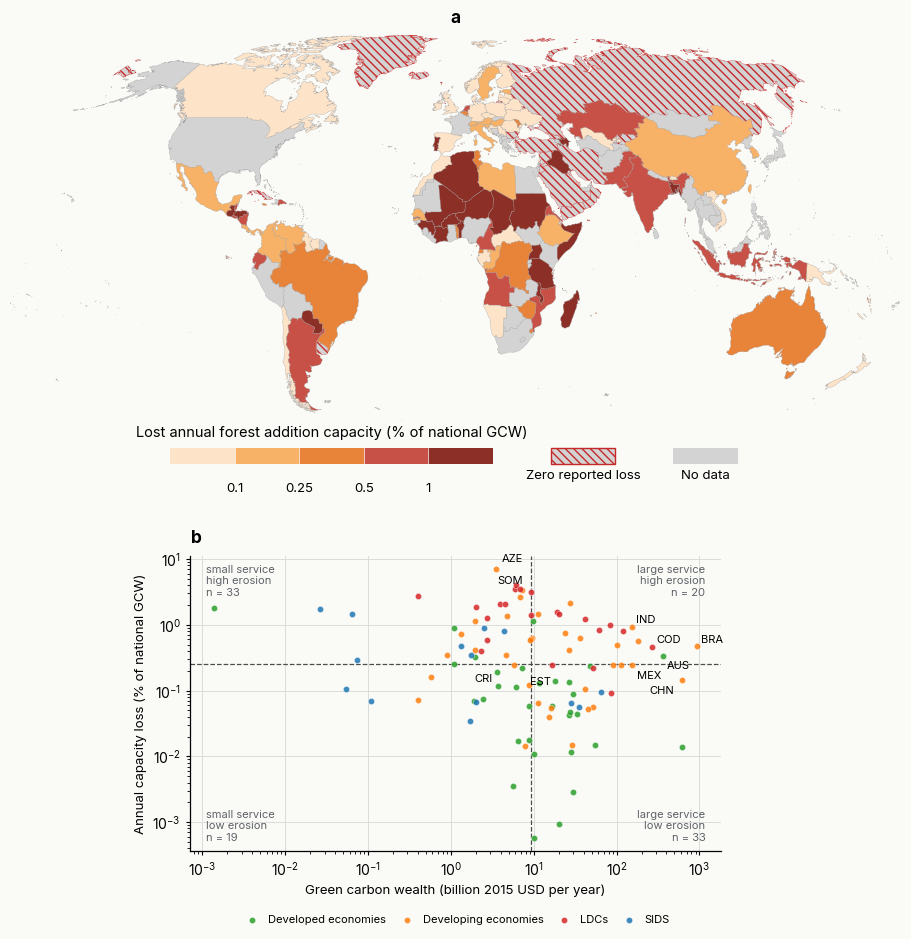

Figure 4 caption:
Fig. 4: Geographic inequality in forest carbon-removal capacity erosion. a. Map of reported annual capacity loss. b. Relationship between GCW and relative erosion, with selected country labels across the four quadrants.


In [9]:
# Figure 4: Geographic inequality in forest carbon-removal capacity erosion.
EROSION_COLS = ["#fde3c8", "#f7b267", "#e8833a", "#c75146", "#8c2f26"]

fig = plt.figure(figsize=(14.5, 10.6), facecolor=BG)
grid = fig.add_gridspec(2, 4, height_ratios=[1.30, 1], hspace=0.40, wspace=0.26)

# (a) map of erosion intensity
ax = fig.add_subplot(grid[0, :])
ax.set_facecolor(BG)
zero_mask = (base.set_index("iso3")["reported"] &
             base.set_index("iso3")["erosion_pct"].eq(0))
class_map(ax, base.set_index("iso3")["erosion_pct"].replace(0, np.nan),
          bins=[0, 0.1, 0.25, 0.5, 1.0, np.inf], ticks=["0.1", "0.25", "0.5", "1"],
          colors=EROSION_COLS,
          legend_title="Lost annual forest addition capacity (% of national GCW)",
          extra_cats=[(zero_mask, "Zero reported loss", MISSING_COLOR, ZERO_HATCH)],
          legend_box=(0.18, -0.16, 0.64, 0.13), legend_gap=0.9)
panel(ax, "a", "Geographic intensity of forest carbon-removal capacity loss", loc="center")

# (b) service versus erosion typology
ax = fig.add_subplot(grid[1, 1:3])
clean(ax, grid_axis="both", spines=("left", "bottom"))
t = base.dropna(subset=["gcw_usd2015_yr_mean", "erosion_pct"]).query(
    "gcw_usd2015_yr_mean > 0 and erosion_pct > 0")
if len(t) != 105:
    raise ValueError(f"Expected 105 positive-loss units, found {len(t)}")
med_g, med_e = t["gcw_usd2015_yr_mean"].median(), t["erosion_pct"].median()
for g_name, d in t.groupby("groups"):
    ax.scatter(d["gcw_usd2015_yr_mean"] / 1e9, d["erosion_pct"], s=20, alpha=0.85, zorder=3,
               color=GROUP_COLORS.get(g_name, "grey"), label=g_name, edgecolor="white", linewidth=0.3)
# Keep the original four large-service/high-erosion labels. Add the two
# largest absolute annual capacity losses in each of the other quadrants.
quadrant_masks = {
    "large_high": t["gcw_usd2015_yr_mean"].ge(med_g) & t["erosion_pct"].ge(med_e),
    "large_low": t["gcw_usd2015_yr_mean"].ge(med_g) & t["erosion_pct"].lt(med_e),
    "small_high": t["gcw_usd2015_yr_mean"].lt(med_g) & t["erosion_pct"].ge(med_e),
    "small_low": t["gcw_usd2015_yr_mean"].lt(med_g) & t["erosion_pct"].lt(med_e),
}
label_limits = {"large_high": 4, "large_low": 2, "small_high": 2, "small_low": 2}
label_offsets = {
    "BRA": (3, 3), "IND": (3, 3), "COD": (3, 3), "AUS": (3, -9),
    "CHN": (-23, -10), "MEX": (4, -10),
    "SOM": (-24, 6), "AZE": (4, 5),
    "EST": (6, -12), "CRI": (-28, -12),
}
labelled = []
for quadrant, mask in quadrant_masks.items():
    selected = t.loc[mask].nlargest(label_limits[quadrant], "loss_usd")
    for _, row in selected.iterrows():
        code = row["iso3"]
        ax.annotate(code, (row["gcw_usd2015_yr_mean"] / 1e9, row["erosion_pct"]),
                    fontsize=8, color=TEXT, xytext=label_offsets.get(code, (3, 3)),
                    textcoords="offset points", zorder=4)
        labelled.append((quadrant, code))
print("Figure 4 labels by quadrant:", labelled)
ax.axvline(med_g / 1e9, color=MUTED, ls="--", lw=0.9, zorder=2)
ax.axhline(med_e, color=MUTED, ls="--", lw=0.9, zorder=2)
ax.set_xscale("log")
ax.set_yscale("log")
counts = {
    "large service\nlow erosion": ((t["gcw_usd2015_yr_mean"] >= med_g) & (t["erosion_pct"] < med_e)).sum(),
    "large service\nhigh erosion": ((t["gcw_usd2015_yr_mean"] >= med_g) & (t["erosion_pct"] >= med_e)).sum(),
    "small service\nlow erosion": ((t["gcw_usd2015_yr_mean"] < med_g) & (t["erosion_pct"] < med_e)).sum(),
    "small service\nhigh erosion": ((t["gcw_usd2015_yr_mean"] < med_g) & (t["erosion_pct"] >= med_e)).sum(),
}
corners = {"large service\nlow erosion": (0.97, 0.03, "right", "bottom"),
           "large service\nhigh erosion": (0.97, 0.97, "right", "top"),
           "small service\nlow erosion": (0.03, 0.03, "left", "bottom"),
           "small service\nhigh erosion": (0.03, 0.97, "left", "top")}
for key, (fx, fy, ha, va) in corners.items():
    ax.text(fx, fy, f"{key}\nn = {counts[key]}", transform=ax.transAxes, fontsize=8,
            ha=ha, va=va, color=TEXT2)
ax.set_xlabel("Green carbon wealth (billion 2015 USD per year)", fontsize=9.5)
ax.set_ylabel("Annual capacity loss (% of national GCW)", fontsize=9.5)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18), columnspacing=0.9, handletextpad=0.4)
panel(ax, "b", "GCW versus relative erosion (n=105)")


save(fig, "Figure4")
plt.show()
print("Figure 4 caption:\nFig. 4: Geographic inequality in forest carbon-removal capacity erosion. a. Map of reported annual capacity loss. b. Relationship between GCW and relative erosion, with selected country labels across the four quadrants.")


## Allocation concentration and reforestation opportunities

**A** ranks all 236 national allocations under the hypothetical rule of 2% of annual GCW and traces the complete cumulative curve. **B** shows the country-level dispersion within each economic group; the totals at right are group aggregates and the two unclassified units are displayed so all 236 units reconcile.

The 2% rule is hypothetical and not an observed funding need. A separate country-level analysis compares annual forest-capacity loss with reconstructed reforestation opportunities. The supplementary diagnostic is retained to show the marginal-price distribution and the allocation-versus-uniform-payment comparison.

[skipped] Supplementary_Figure5_reforestation_detail


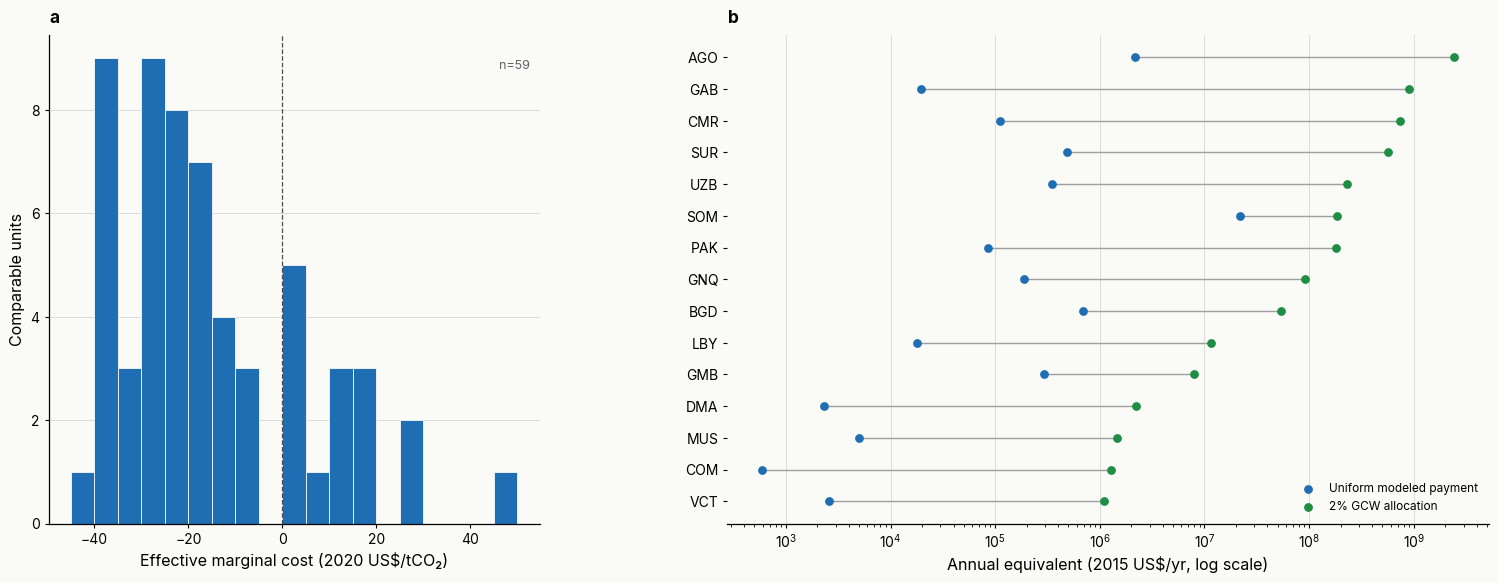

Supplementary Figure 5 caption:
Fig. S5: Reconstructed reforestation comparison. a. Distribution of reconstructed marginal prices for the 59 units with an attainable target. b. Hypothetical 2% GCW allocations compared with modeled uniform payments in the 15 positive-price cases. These scenario values are not observed funding needs, replacement costs, or a funding gap.


[skipped] Candidate_Figure5_loss_reforestation_opportunities


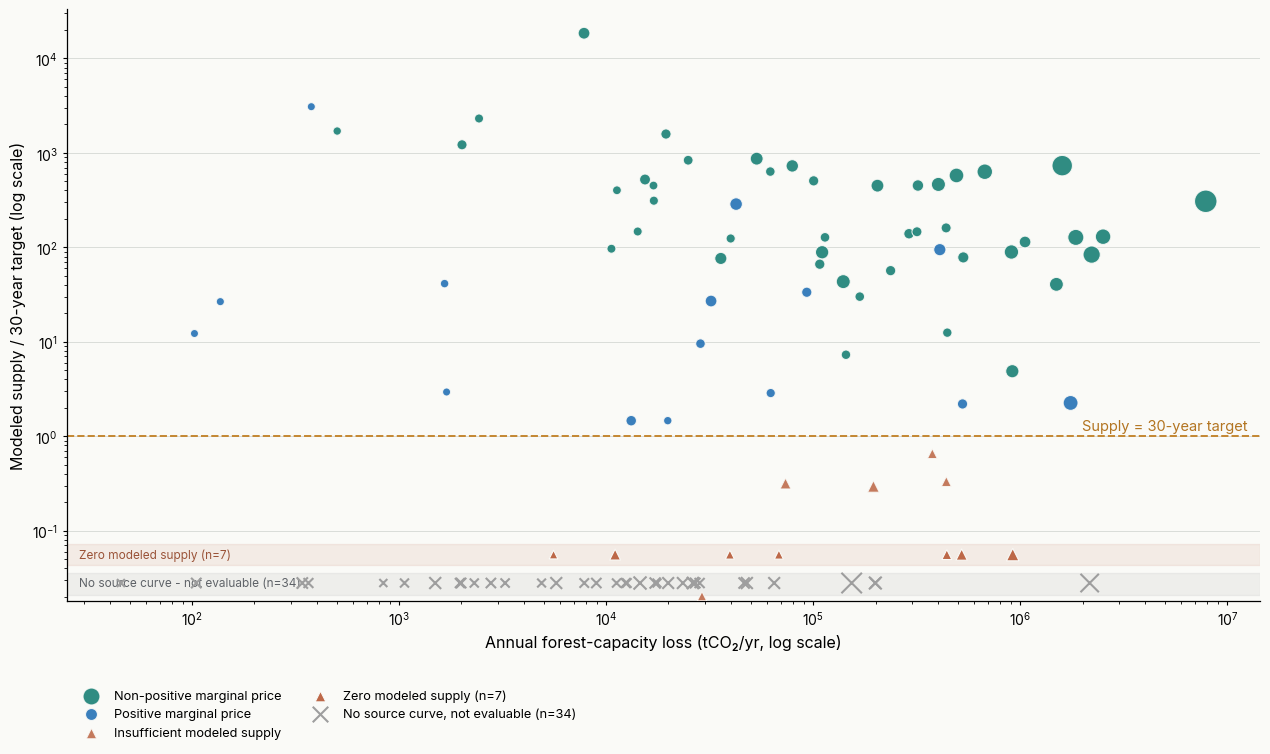

Figure 5 caption:
Fig. 5: Country-level forest-capacity loss and reforestation opportunities. The x-axis shows annual forest-capacity loss, the y-axis shows modeled supply relative to the 30-year target, the dashed line marks supply equal to the target, and point size represents the hypothetical 2% GCW allocation. Units without a source curve are not evaluable; zero-supply units are shown separately.
[skipped] Candidate_Figure4C_alternatives


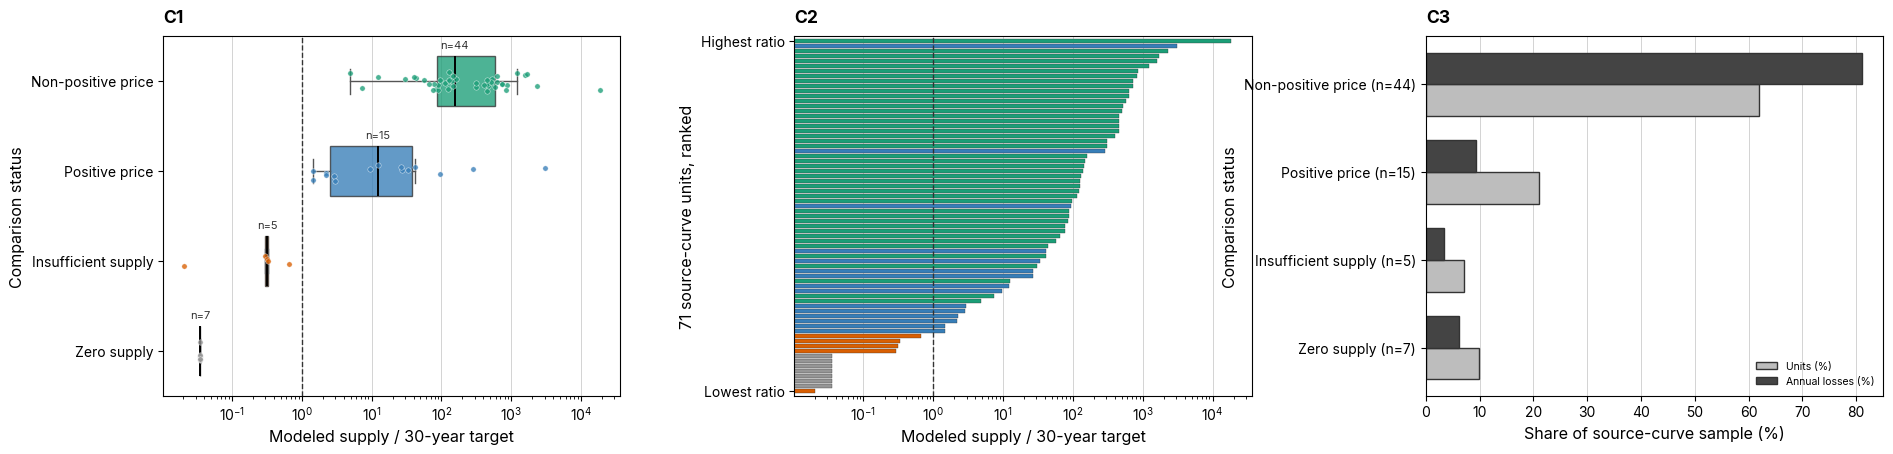

Figure 4 C alternatives caption:
C1. Distribution of modeled supply relative to the 30-year target by comparison status, with individual units overlaid. C2. Ranked unit-level ratios. C3. Sample-size and annual-loss coverage by status. These are candidate alternatives for panel C and use the same 71 source-curve units.


In [10]:
# Rebuild the figure's audit tables before plotting; source data stay unchanged.
import json
import subprocess
import sys

subprocess.run([sys.executable, str(ROOT / "code/scripts/build_finance_figure4.py")],
               cwd=ROOT, check=True, capture_output=True, text=True)
finance = pd.read_csv(TABLES / "Supplementary_Figure4_finance_allocations_by_unit.csv")
finance_groups = pd.read_csv(TABLES / "Supplementary_Figure4_finance_allocations_by_group.csv")
busch_prices = pd.read_csv(TABLES / "Supplementary_Figure4_Busch_marginal_prices_by_unit.csv")
finance_summary = json.loads((VALIDATION / "finance_figure4_summary.json").read_text(encoding="utf-8"))
BUSCH_RECON = ROOT / "data" / "outputs" / "busch_reconstruction"
recon_country = pd.read_csv(BUSCH_RECON / "busch_mangrove_refresh_20261023_country_finance.csv")
coverage105 = pd.read_csv(BUSCH_RECON / "busch_mangrove_refresh_20261023_coverage_105.csv")

if finance["iso3"].nunique() != 236 or len(busch_prices) != 105:
    raise ValueError("Figure 4 input coverage differs from the validated sample")
if not np.isclose(finance["cumulative_share_pct"].iloc[-1], 100):
    raise ValueError("National finance allocation does not sum to 100%")

fig = plt.figure(figsize=(15.2, 7.3), facecolor=BG)
outer = fig.add_gridspec(1, 2, width_ratios=[1.10, 1.45], wspace=0.28,
                         left=0.065, right=0.985, bottom=0.17, top=0.85)

# A. Full national curve, including the zero-allocated units at its right end.
ax_a = fig.add_subplot(outer[0])
clean(ax_a, grid_axis="y", spines=("left", "bottom"))
ranks = np.r_[0, finance["allocation_rank"].to_numpy()]
shares = np.r_[0, finance["cumulative_share_pct"].to_numpy()]
ax_a.plot(ranks, shares, color=GREEN, lw=2.4, zorder=3)
for n, label in [(10, "Top 10"), (50, "Top 50")]:
    share = float(finance.loc[finance.allocation_rank.eq(n), "cumulative_share_pct"].iloc[0])
    ax_a.scatter([n], [share], s=34, color=GREEN, edgecolor=BG, zorder=4)
    ax_a.plot([n, n], [0, share], color=EDGE_GREY, ls="--", lw=0.8, zorder=1)
    ax_a.annotate(f"{label}: {share:.1f}%", (n, share), xytext=(7, -20 if n == 10 else 9),
                  textcoords="offset points", fontsize=9.5, color=TEXT)
ax_a.set(xlim=(0, 236), ylim=(0, 103), xlabel="Countries and territories, ranked by allocation",
         ylabel="Cumulative share of allocation (%)")
ax_a.set_xticks([0, 10, 50, 100, 150, 200, 236])
ax_a.set_yticks([0, 25, 50, 75, 100])
panel(ax_a, "a", "Concentration across 236 units")

# B. National dispersion is separate from each group's aggregate total.
inner_b = outer[1].subgridspec(1, 2, width_ratios=[4.3, 1.1], wspace=0.04)
ax_b = fig.add_subplot(inner_b[0])
ax_b_total = fig.add_subplot(inner_b[1], sharey=ax_b)
clean(ax_b, grid_axis="x", spines=("bottom",))
group_order = [g for g in ["Developed economies", "Developing economies", "LDCs", "SIDS", "Unclassified"]
               if g in set(finance.group_display)]
group_colors = [GROUP_COLORS.get(g, EDGE_GREY) for g in group_order]
samples = [finance.loc[finance.group_display.eq(g), "our_2pct_gcw_allocation_usd2015_yr"].to_numpy() / 1e6
           for g in group_order]
box = ax_b.boxplot(samples, vert=False, positions=np.arange(1, len(group_order) + 1), widths=0.55,
                   patch_artist=True, showfliers=True,
                   flierprops={"marker": ".", "markersize": 3, "markeredgecolor": MUTED},
                   medianprops={"color": TEXT, "linewidth": 1.3},
                   whiskerprops={"color": EDGE_GREY}, capprops={"color": EDGE_GREY})
for patch, color in zip(box["boxes"], group_colors):
    patch.set(facecolor=color, alpha=0.70, edgecolor=color)
ax_b.set_xscale("symlog", linthresh=1)
ax_b.set_xlim(0, 30000)
ax_b.set_xticks([0, 1, 10, 100, 1000, 10000])
ax_b.set_xticklabels(["0", "1", "10", "100", "1,000", "10,000"])
ax_b.set_yticks(np.arange(1, len(group_order) + 1), [f"{g}  (n={len(v)})" for g, v in zip(group_order, samples)])
ax_b.invert_yaxis()
ax_b.set_xlabel("National allocation (million 2015 US$/yr)")
panel(ax_b, "b", "Country dispersion by group")
ax_b_total.set_facecolor(BG)
ax_b_total.set_xlim(0, 1)
ax_b_total.set_xticks([])
ax_b_total.tick_params(left=False, labelleft=False)
for spine in ax_b_total.spines.values():
    spine.set_visible(False)
ax_b_total.text(0.0, 0.94, "Group total\nUS$ bn/yr", transform=ax_b_total.transAxes,
                ha="left", va="bottom", color=TEXT2, fontsize=8.5)
for i, group_name in enumerate(group_order, start=1):
    aggregate = float(finance_groups.loc[finance_groups.group_display.eq(group_name),
                                         "total_usd2015_yr"].iloc[0]) / 1e9
    shown_total = f"{aggregate:.3f}" if aggregate < 0.01 else f"{aggregate:.2f}"
    ax_b_total.text(0.0, i, shown_total, ha="left", va="center", fontsize=9.5, color=TEXT)

plt.close(fig)

# Figure 5 - supplementary detail for the reconstructed reforestation comparison.
comparable = recon_country.loc[
    recon_country["status"].eq("target_within_cell_supply")
].copy()
positive_price = comparable.loc[
    comparable["marginal_effective_cost_usd2015_per_discounted_tco2"].gt(0)
].copy()
if len(comparable) != 59 or len(positive_price) != 15:
    raise ValueError("Figure 5 reconstruction coverage differs from the validated sample")
fig5 = plt.figure(figsize=(16.0, 7.4), facecolor=BG)
grid5 = fig5.add_gridspec(1, 2, width_ratios=[1.0, 1.55], wspace=0.30,
                           left=0.08, right=0.98, bottom=0.18, top=0.84)

# A. Marginal effective prices for all 59 comparable units.
ax5a = fig5.add_subplot(grid5[0])
clean(ax5a, grid_axis="y", spines=("left", "bottom"))
prices59 = comparable["marginal_effective_cost_usd2015_per_discounted_tco2"].to_numpy()
bins = np.arange(-45, 51, 5)
ax5a.hist(prices59, bins=bins, color=BLUE, edgecolor=BG, linewidth=0.6)
ax5a.axvline(0, color=MUTED, ls="--", lw=0.9)
ax5a.set_xlabel("Effective marginal cost (2015 US$/tCO₂)")
ax5a.set_ylabel("Comparable units")
ax5a.text(0.98, 0.95, "n=59", transform=ax5a.transAxes, ha="right", va="top",
           fontsize=9, color=TEXT2)
panel(ax5a, "a", "Distribution of reconstructed marginal prices")

# B. Allocation versus the modeled uniform payment in the 15 positive-price cases.
ax5b = fig5.add_subplot(grid5[1])
clean(ax5b, grid_axis="x", spines=("bottom",))
positive_price = positive_price.sort_values("allocation_2pct_gcW_usd2015_yr")
y = np.arange(len(positive_price))
allocation = positive_price["allocation_2pct_gcW_usd2015_yr"].to_numpy()
payment = positive_price["uniform_carbon_payment_annual_usd2015"].to_numpy()
ax5b.hlines(y, payment, allocation, color=EDGE_GREY, lw=1.0, zorder=1)
ax5b.scatter(payment, y, color=BLUE, s=28, label="Uniform modeled payment", zorder=3)
ax5b.scatter(allocation, y, color=GREEN, s=28, label="2% GCW allocation", zorder=3)
ax5b.set_xscale("log")
ax5b.set_yticks(y, positive_price["iso3"])
ax5b.set_xlabel("Annual equivalent (2015 US$/yr, log scale)")
ax5b.legend(frameon=False, fontsize=8.5, loc="lower right")
panel(ax5b, "b", "2% allocations and modeled uniform payments in the 15 positive-price cases")
save(fig5, "Supplementary_Figure5_reforestation_detail")
plt.show()
print("Supplementary Figure 5 caption:\nFig. S5: Reconstructed reforestation comparison. a. Distribution of reconstructed marginal prices for the 59 units with an attainable target. b. Hypothetical 2% GCW allocations compared with modeled uniform payments in the 15 positive-price cases. These scenario values are not observed funding needs, replacement costs, or a funding gap.")

# Figure 5 - country-level loss and reforestation opportunities.
# The existing Supplementary_Figure5 above is intentionally retained unchanged.
opportunity = coverage105.rename(columns={
    "our_2pct_gcw_allocation_usd2015_yr": "allocation_2pct_gcW_usd2015_yr",
    "lost_capacity_tco2_yr": "annual_loss_tco2",
}).copy()
opportunity["supply_target_ratio"] = (
    opportunity["available_discounted_tco2"] / opportunity["target_discounted_30yr_tco2"]
)
opportunity["allocation_size"] = (
    32 + 230 * np.sqrt(opportunity["allocation_2pct_gcW_usd2015_yr"] /
                       opportunity["allocation_2pct_gcW_usd2015_yr"].max())
)
no_curve = opportunity["status"].eq("no_published_country_curve")
insufficient = opportunity["status"].eq("target_outside_cell_supply")
zero_supply = insufficient & opportunity["available_discounted_tco2"].fillna(0).eq(0)
short_supply = insufficient & ~zero_supply
nonpositive = (opportunity["status"].eq("target_within_cell_supply")
               & opportunity["marginal_effective_cost_usd2015_per_discounted_tco2"].le(0))
positive = (opportunity["status"].eq("target_within_cell_supply")
            & opportunity["marginal_effective_cost_usd2015_per_discounted_tco2"].gt(0))
if not (no_curve.sum() == 34 and zero_supply.sum() == 7 and
        short_supply.sum() == 5 and nonpositive.sum() == 44 and positive.sum() == 15):
    raise ValueError("Figure 5 status counts differ from the validated reconstruction")
fig5_main, ax5 = plt.subplots(figsize=(12.8, 8.0), facecolor=BG)
clean(ax5, grid_axis="y", spines=("left", "bottom"))
ax5.set_xscale("log")
ax5.set_yscale("log")

# Numeric ratios: 59 target-within-supply units plus the five positive-supply short cases.
for mask, color, label in [
    (nonpositive, "#147d72", "Non-positive marginal price"),
    (positive, BLUE, "Positive marginal price"),
    (short_supply, "#bd6848", "Insufficient modeled supply"),
]: 
    subset = opportunity.loc[mask & opportunity["supply_target_ratio"].gt(0)]
    marker = "^" if label == "Insufficient modeled supply" else "o"
    ax5.scatter(subset["annual_loss_tco2"], subset["supply_target_ratio"],
                s=subset["allocation_size"], marker=marker, color=color,
                alpha=0.88, edgecolor=BG, linewidth=0.8, label=label, zorder=4)

# Dedicated visual bands: zero modeled supply is not the same as no source curve.
ax5.axhspan(0.043, 0.073, color="#bd6848", alpha=0.10, zorder=0)
ax5.axhspan(0.021, 0.036, color=EDGE_GREY, alpha=0.13, zorder=0)
ax5.scatter(opportunity.loc[zero_supply, "annual_loss_tco2"],
            np.full(int(zero_supply.sum()), 0.056),
            s=opportunity.loc[zero_supply, "allocation_size"], marker="^",
            color="#bd6848", edgecolor=BG, linewidth=0.8,
            label="Zero modeled supply (n=7)", zorder=5)
ax5.scatter(opportunity.loc[no_curve, "annual_loss_tco2"],
            np.full(int(no_curve.sum()), 0.028),
            s=opportunity.loc[no_curve, "allocation_size"], marker="x",
            color=EDGE_GREY, linewidth=1.5,
            label="No source curve, not evaluable (n=34)", zorder=5)
ax5.axhline(1, color="#c48732", ls="--", lw=1.4, zorder=2)
ax5.text(0.99, 1.08, "Supply = 30-year target", transform=ax5.get_yaxis_transform(),
         ha="right", va="bottom", fontsize=10.5, color="#b37522")
ax5.text(0.01, 0.056, "Zero modeled supply (n=7)", transform=ax5.get_yaxis_transform(),
         ha="left", va="center", fontsize=8.5, color="#9b5439")
ax5.text(0.01, 0.028, "No source curve - not evaluable (n=34)",
         transform=ax5.get_yaxis_transform(), ha="left", va="center",
         fontsize=8.5, color=TEXT2)
ax5.set_ylim(0.018, max(20, float(opportunity["supply_target_ratio"].max()) * 1.8))
ax5.set_xlabel("Annual forest-capacity loss (tCO₂/yr, log scale)")
ax5.set_ylabel("Modeled supply / 30-year target (log scale)")
ax5.legend(frameon=False, fontsize=9.2, loc="upper left", bbox_to_anchor=(0.0, -0.13),
           ncol=2)
fig5_main.tight_layout(rect=(0, 0.02, 1, 0.98))
save(fig5_main, "Candidate_Figure5_loss_reforestation_opportunities")
plt.show()
print("Figure 5 caption:\nFig. 5: Country-level forest-capacity loss and reforestation opportunities. The x-axis shows annual forest-capacity loss, the y-axis shows modeled supply relative to the 30-year target, the dashed line marks supply equal to the target, and point size represents the hypothetical 2% GCW allocation. Units without a source curve are not evaluable; zero-supply units are shown separately.")

candidate = coverage105.rename(columns={
    "our_2pct_gcw_allocation_usd2015_yr": "allocation_2pct_gcW_usd2015_yr",
    "lost_capacity_tco2_yr": "annual_loss_tco2",
}).copy()
candidate["supply_target_ratio"] = candidate["available_discounted_tco2"] / candidate["target_discounted_30yr_tco2"]
candidate["allocation_size"] = 28 + 180 * np.sqrt(candidate["allocation_2pct_gcW_usd2015_yr"] / candidate["allocation_2pct_gcW_usd2015_yr"].max())
no_curve = candidate["status"].eq("no_published_country_curve")
insufficient = candidate["status"].eq("target_outside_cell_supply")
zero_supply = insufficient & candidate["available_discounted_tco2"].fillna(0).eq(0)
short_supply = insufficient & ~zero_supply
nonpositive = candidate["status"].eq("target_within_cell_supply") & candidate["marginal_effective_cost_usd2015_per_discounted_tco2"].le(0)
positive = candidate["status"].eq("target_within_cell_supply") & candidate["marginal_effective_cost_usd2015_per_discounted_tco2"].gt(0)
reachable = candidate.loc[candidate["status"].eq("target_within_cell_supply")].copy()
if not (len(candidate.loc[~no_curve]) == 71 and len(reachable) == 59 and zero_supply.sum() == 7):
    raise ValueError("Additional Figure 4 candidate coverage differs from the validated reconstruction")

# Alternative panel-C diagnostics, retained separately for visual comparison.
c_alt = candidate.loc[~no_curve].copy()
c_alt["status_label"] = np.select([zero_supply.loc[c_alt.index], short_supply.loc[c_alt.index], positive.loc[c_alt.index]], ["Zero supply", "Insufficient supply", "Positive price"], default="Non-positive price")
c_alt["ratio_plot"] = c_alt["supply_target_ratio"].where(c_alt["supply_target_ratio"].gt(0), 0.035)
status_order = ["Non-positive price", "Positive price", "Insufficient supply", "Zero supply"]
status_colors = {"Non-positive price": "#1b9e77", "Positive price": "#377eb8", "Insufficient supply": "#d95f02", "Zero supply": "#969696"}
fig_c_alts, alt_axes = plt.subplots(1, 3, figsize=(18.5, 5.8), facecolor="white", constrained_layout=False)
fig_c_alts.subplots_adjust(left=0.055, right=0.985, bottom=0.18, top=0.80, wspace=0.38)
# C1. Horizontal boxplots: compact distributional summary by status.
ax_c1 = alt_axes[0]; ax_c1.set_facecolor("white")
box_data = [c_alt.loc[c_alt["status_label"].eq(s), "ratio_plot"] for s in status_order]
bp = ax_c1.boxplot(box_data, vert=False, positions=np.arange(1, len(status_order) + 1), widths=0.55, patch_artist=True, showfliers=False, medianprops={"color": "black", "linewidth": 1.4}, whiskerprops={"color": "#555555"}, capprops={"color": "#555555"})
for patch, s in zip(bp["boxes"], status_order): patch.set(facecolor=status_colors[s], alpha=0.78, edgecolor="#333333")
rng_alt = np.random.default_rng(20261026)
for y_pos, s, vals in zip(np.arange(1, len(status_order) + 1), status_order, box_data):
    ax_c1.scatter(vals, y_pos + rng_alt.uniform(-0.11, 0.11, len(vals)), s=15, color=status_colors[s], edgecolor="white", linewidth=0.35, alpha=0.78, zorder=4)
    ax_c1.text(float(np.median(vals)), y_pos - 0.34, f"n={len(vals)}", ha="center", va="bottom", fontsize=8.0, color="#333333")
ax_c1.set_xscale("log"); ax_c1.axvline(1, color="#333333", ls="--", lw=1.0); ax_c1.set_yticks(np.arange(1, 5), status_order); ax_c1.invert_yaxis()
ax_c1.set_xlabel("Modeled supply / 30-year target"); ax_c1.set_ylabel("Comparison status"); ax_c1.grid(axis="x", color="#d0d0d0", linewidth=0.65); ax_c1.set_axisbelow(True); panel(ax_c1, "C1", "Distribution by status", pad=10)

# C2. Ranked horizontal bars: one bar per source-curve unit, without point overlap.
ax_c2 = alt_axes[1]; ax_c2.set_facecolor("white")
ranked = c_alt.sort_values(["ratio_plot", "annual_loss_tco2"], ascending=[True, True]).reset_index(drop=True)
for s in status_order[::-1]:
    sub = ranked.loc[ranked["status_label"].eq(s)]
    ax_c2.barh(sub.index, sub["ratio_plot"], color=status_colors[s], edgecolor="#333333", linewidth=0.25, height=0.78, label=s)
ax_c2.set_xscale("log"); ax_c2.axvline(1, color="#333333", ls="--", lw=1.0); ax_c2.set_ylim(-1, len(ranked)); ax_c2.set_yticks([0, len(ranked)-1], ["Lowest ratio", "Highest ratio"]); ax_c2.set_xlabel("Modeled supply / 30-year target"); ax_c2.set_ylabel("71 source-curve units, ranked"); ax_c2.grid(axis="x", color="#d0d0d0", linewidth=0.65); ax_c2.set_axisbelow(True); panel(ax_c2, "C2", "Ranked units", pad=10)

# C3. Aggregated bars: sample size and annual-loss coverage by status.
ax_c3 = alt_axes[2]; ax_c3.set_facecolor("white")
agg = c_alt.groupby("status_label", sort=False).agg(n=("iso3", "size"), loss=("annual_loss_tco2", "sum")).reindex(status_order).fillna(0)
agg["n_share"] = 100 * agg["n"] / agg["n"].sum(); agg["loss_share"] = 100 * agg["loss"] / agg["loss"].sum()
y_agg = np.arange(len(status_order)); h = 0.36
ax_c3.barh(y_agg + h/2, agg["n_share"], height=h, color="#bdbdbd", edgecolor="#333333", label="Units (%)")
ax_c3.barh(y_agg - h/2, agg["loss_share"], height=h, color="#444444", edgecolor="#333333", label="Annual losses (%)")
ax_c3.set_yticks(y_agg, [f"{s} (n={int(agg.loc[s, 'n'])})" for s in status_order]); ax_c3.invert_yaxis(); ax_c3.set_xlabel("Share of source-curve sample (%)"); ax_c3.set_ylabel("Comparison status"); ax_c3.grid(axis="x", color="#d0d0d0", linewidth=0.65); ax_c3.set_axisbelow(True); ax_c3.legend(frameon=False, fontsize=7.5, loc="lower right"); panel(ax_c3, "C3", "Aggregated sample coverage", pad=10)

save(fig_c_alts, "Candidate_Figure4C_alternatives")
plt.show()
print("Figure 4 C alternatives caption:\nC1. Distribution of modeled supply relative to the 30-year target by comparison status, with individual units overlaid. C2. Ranked unit-level ratios. C3. Sample-size and annual-loss coverage by status. These are candidate alternatives for panel C and use the same 71 source-curve units.")

[saved] Figure5.png


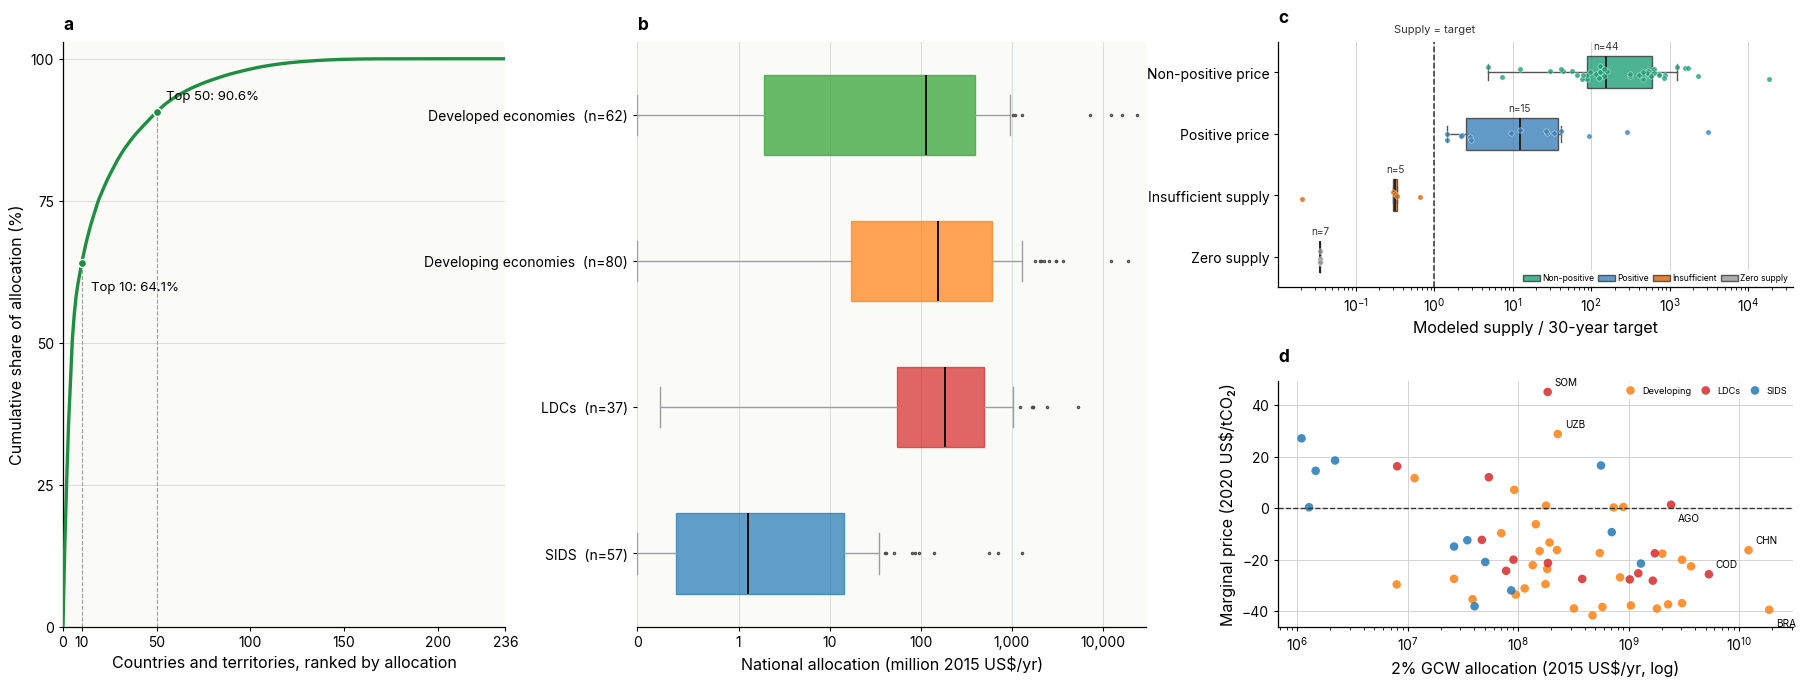

Figure 5 caption:
Fig. 5: GCW-based climate-finance allocations and reforestation opportunities. a. Cumulative concentration of the hypothetical 2% GCW allocation across 236 accounting units. b. National allocations by economic group. c. Modeled reforestation supply relative to the 30-year target for the 71 units with source curves; the dashed line marks supply equal to the target. d. Reconstructed marginal costs plotted against the hypothetical allocation for the 59 units with attainable targets. The 2% rule is hypothetical, and the Busch quantities are reconstructed scenario outputs, not observed funding needs.


In [11]:
# Figure 5: GCW-based climate-finance allocations and reforestation opportunities.
fig4_abcd = plt.figure(figsize=(18.8, 8.6), facecolor="white")
grid4 = fig4_abcd.add_gridspec(1, 3, width_ratios=[1.00, 1.15, 1.1625], wspace=0.27,
                               left=0.065, right=0.985, bottom=0.17, top=0.85)
# Reuse the current A and B without changing their existing figure.
ax4a = fig4_abcd.add_subplot(grid4[0])
clean(ax4a, grid_axis="y", spines=("left", "bottom"))
ax4a.plot(ranks, shares, color=GREEN, lw=2.4, zorder=3)
for n, label in [(10, "Top 10"), (50, "Top 50")]:
    share = float(finance.loc[finance.allocation_rank.eq(n), "cumulative_share_pct"].iloc[0])
    ax4a.scatter([n], [share], s=34, color=GREEN, edgecolor=BG, zorder=4)
    ax4a.plot([n, n], [0, share], color=EDGE_GREY, ls="--", lw=0.8, zorder=1)
    ax4a.annotate(f"{label}: {share:.1f}%", (n, share), xytext=(7, -20 if n == 10 else 9),
                  textcoords="offset points", fontsize=9.5, color=TEXT)
ax4a.set(xlim=(0, 236), ylim=(0, 103), xlabel="Countries and territories, ranked by allocation",
         ylabel="Cumulative share of allocation (%)")
ax4a.set_xticks([0, 10, 50, 100, 150, 200, 236]); ax4a.set_yticks([0, 25, 50, 75, 100])
panel(ax4a, "a", "Concentration across 236 units")

ax4b = fig4_abcd.add_subplot(grid4[1])
clean(ax4b, grid_axis="x", spines=("bottom",))
box = ax4b.boxplot(samples, vert=False, positions=np.arange(1, len(group_order) + 1), widths=0.55,
                   patch_artist=True, showfliers=True,
                   flierprops={"marker": ".", "markersize": 3, "markeredgecolor": MUTED},
                   medianprops={"color": TEXT, "linewidth": 1.3},
                   whiskerprops={"color": EDGE_GREY}, capprops={"color": EDGE_GREY})
for patch, color in zip(box["boxes"], group_colors):
    patch.set(facecolor=color, alpha=0.70, edgecolor=color)
ax4b.set_xscale("symlog", linthresh=1); ax4b.set_xlim(0, 30000)
ax4b.set_xticks([0, 1, 10, 100, 1000, 10000]); ax4b.set_xticklabels(["0", "1", "10", "100", "1,000", "10,000"])
ax4b.set_yticks(np.arange(1, len(group_order) + 1), group_order)
# Centre each count above the box (Q1-Q3), not above the whiskers.
x_transform = ax4b.xaxis.get_transform()
for y_pos, values in enumerate(samples, start=1):
    q1, q3 = np.percentile(values, [25, 75])
    x_box = x_transform.inverted().transform(np.mean(x_transform.transform([q1, q3])))
    ax4b.text(x_box, y_pos - 0.34, f"n={len(values)}", ha="center", va="bottom",
              fontsize=8.5, color=TEXT)
ax4b.invert_yaxis(); ax4b.set_xlabel("National allocation (million 2015 US$/yr)")
panel(ax4b, "b", "Country dispersion by group")

inner4 = grid4[2].subgridspec(2, 1, height_ratios=[1, 1], hspace=0.38)
ax4c = fig4_abcd.add_subplot(inner4[0]); clean(ax4c, grid_axis=None, spines=("left", "bottom")); ax4c.set_facecolor("white")
c_candidate = candidate.loc[~no_curve].copy()
c_candidate["status_label"] = np.select([zero_supply.loc[c_candidate.index], short_supply.loc[c_candidate.index], positive.loc[c_candidate.index]], ["Zero supply", "Insufficient supply", "Positive price"], default="Non-positive price")
c_candidate["ratio_plot"] = c_candidate["supply_target_ratio"].where(c_candidate["supply_target_ratio"].gt(0), 0.035)
c_order = ["Non-positive price", "Positive price", "Insufficient supply", "Zero supply"]
c_colors = {"Non-positive price": "#1b9e77", "Positive price": "#377eb8", "Insufficient supply": "#d95f02", "Zero supply": "#969696"}
c_box_data = [c_candidate.loc[c_candidate["status_label"].eq(s), "ratio_plot"] for s in c_order]
c_box = ax4c.boxplot(c_box_data, vert=False, positions=np.arange(1, len(c_order) + 1), widths=0.52, patch_artist=True, showfliers=False, medianprops={"color": "#222222", "linewidth": 1.4}, whiskerprops={"color": "#555555"}, capprops={"color": "#555555"})
for patch, s in zip(c_box["boxes"], c_order): patch.set(facecolor=c_colors[s], alpha=0.78, edgecolor="#333333")
rng_c = np.random.default_rng(20261026)
for y_pos, s, vals in zip(np.arange(1, len(c_order) + 1), c_order, c_box_data):
    sub = c_candidate.loc[c_candidate["status_label"].eq(s)]
    ax4c.scatter(sub["ratio_plot"], y_pos + rng_c.uniform(-0.11, 0.11, len(sub)), s=15, color=c_colors[s], edgecolor="white", linewidth=0.35, alpha=0.78, zorder=4)
    ax4c.text(float(np.median(vals)), y_pos - 0.34, f"n={len(vals)}", ha="center", va="bottom", fontsize=7.2, color="#333333")
ax4c.set_xscale("log"); ax4c.axvline(1, color="#333333", ls="--", lw=1.1); ax4c.text(1, 1.03, "Supply = target", transform=ax4c.get_xaxis_transform(), ha="center", va="bottom", fontsize=8.0, color="#333333")
ax4c.set_yticks(np.arange(1, len(c_order) + 1), c_order); ax4c.invert_yaxis(); ax4c.set_xlabel("Modeled supply / 30-year target"); ax4c.set_ylabel("")
ax4c.grid(axis="x", color="#d0d0d0", linewidth=0.65, zorder=0); ax4c.set_axisbelow(True)
ax4c.legend([Patch(facecolor=c_colors[s], edgecolor="#333333", alpha=0.78) for s in c_order], ["Non-positive", "Positive", "Insufficient", "Zero supply"], frameon=True, facecolor="white", framealpha=0.78, edgecolor="none", fontsize=6.2, loc="lower right", bbox_to_anchor=(1.0, 0.0), ncol=4, columnspacing=0.45, handletextpad=0.25, borderaxespad=0.15, labelspacing=0.2); panel(ax4c, "c", "Reforestation supply relative to target", pad=14)

ax4d = fig4_abcd.add_subplot(inner4[1]); clean(ax4d, grid_axis=None, spines=("left", "bottom")); ax4d.set_facecolor("white")
group_colors_d = {"Developed economies": GROUP_COLORS["Developed economies"], "Developing economies": GROUP_COLORS["Developing economies"], "LDCs": GROUP_COLORS["LDCs"], "SIDS": GROUP_COLORS["SIDS"]}
group_labels = {"Developed economies": "Developed", "Developing economies": "Developing", "LDCs": "LDCs", "SIDS": "SIDS"}
for group_name in ["Developed economies", "Developing economies", "LDCs", "SIDS"]:
    sub = reachable.loc[reachable["groups"].eq(group_name)]
    if not sub.empty: ax4d.scatter(sub["allocation_2pct_gcW_usd2015_yr"], sub["marginal_effective_cost_usd2015_per_discounted_tco2"], s=38, color=group_colors_d[group_name], edgecolor="none", linewidth=0, alpha=0.84, label=group_labels[group_name])
ax4d.set_xscale("log"); ax4d.axhline(0, color="#333333", ls="--", lw=1.0)
ax4d.set_xlabel("2% GCW allocation (2015 US$/yr, log)"); ax4d.set_ylabel("Marginal price (2015 US$/tCO₂)")
annotate_isos = ["SOM", "UZB", "AGO", "BRA", "CHN", "COD"]
label_offsets = {"SOM": (5, 5), "UZB": (5, 5), "AGO": (5, -12), "BRA": (5, -12), "CHN": (5, 5), "COD": (5, 5)}
for iso3 in dict.fromkeys(annotate_isos):
    row = reachable.loc[reachable["iso3"].eq(iso3)].iloc[0]
    ax4d.annotate(iso3, (row["allocation_2pct_gcW_usd2015_yr"], row["marginal_effective_cost_usd2015_per_discounted_tco2"]), xytext=label_offsets.get(iso3, (5, 5)), textcoords="offset points", fontsize=7.2, color=TEXT)
ax4d.grid(axis="both", color="#d0d0d0", linewidth=0.65, zorder=0); ax4d.set_axisbelow(True)
ax4d.legend(frameon=True, facecolor="white", framealpha=0.78, edgecolor="none", fontsize=6.6, loc="upper right", bbox_to_anchor=(1.0, 1.0), ncol=4, columnspacing=0.55, handletextpad=0.3, borderaxespad=0.15, labelspacing=0.2); panel(ax4d, "d", "Marginal costs and allocations", pad=14)

save(fig4_abcd, "Figure5")
plt.show()
print("Figure 5 caption:\nFig. 5: GCW-based climate-finance allocations and reforestation opportunities. a. Cumulative concentration of the hypothetical 2% GCW allocation across 236 accounting units. b. National allocations by economic group. c. Modeled reforestation supply relative to the 30-year target for the 71 units with source curves; the dashed line marks supply equal to the target. d. Reconstructed marginal costs plotted against the hypothetical allocation for the 59 units with attainable targets. The 2% rule is hypothetical, and the Busch quantities are reconstructed scenario outputs, not observed funding needs.")

## Supplementary diagnostic - coefficients for the three baseline relationships

The panel uses the spatial-review outputs. If the three researcher decisions are recorded in `data/derived/validation/manuscript_spatial_model_selection.csv`, they are used. Otherwise, the panel explicitly displays a **provisional specification**: for each baseline relationship, the converged model with the lowest BIC among the two neighbourhood matrices. In an exact OLS tie, Queen contiguity is shown as a display convention. The figure is not a final scientific model selection and the coefficients are not causal effects.

Provisional minimum-BIC candidates; not final model decisions
               outcome             specification           weight model
lost_capacity_mtco2_yr baseline_2024_same_sample queen_contiguity   OLS
    erosion_pct_of_gcw baseline_2024_same_sample queen_contiguity   OLS
      gcw_gdp_pct_2024 baseline_2024_same_sample queen_contiguity  SDEM
[skipped] Candidate_Supplementary_spatial_associations


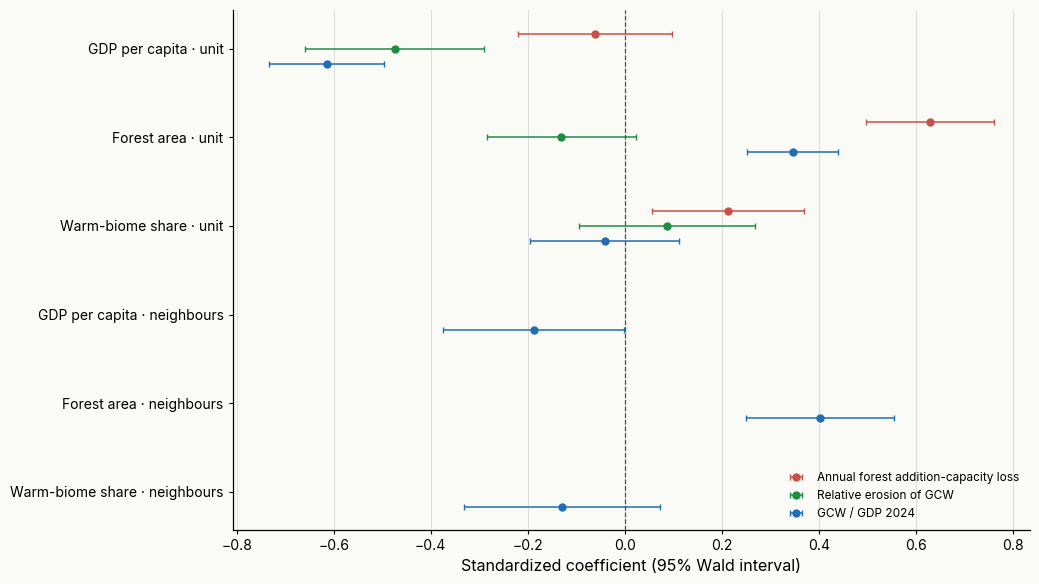

Supplementary spatial-associations caption:
This candidate figure shows standardized associations with carbon wealth and erosion for the provisional model choices. Provisional minimum-BIC candidates; not final model decisions. The panel is descriptive and does not establish causal effects.


In [12]:
selection_file = VALIDATION / "manuscript_spatial_model_selection.csv"
coefficient_file = TABLES / "Supplementary_spatial_candidate_standardized_coefficients.csv"
fit_file = VALIDATION / "spatial_emissions_2024_model_fit.csv"
outcomes = ["lost_capacity_mtco2_yr", "erosion_pct_of_gcw", "gcw_gdp_pct_2024"]

if selection_file.exists():
    chosen_models = pd.read_csv(selection_file)
    required = {"outcome", "specification", "weight", "model"}
    if not required.issubset(chosen_models.columns):
        raise ValueError(f"Model-selection file must contain {sorted(required)}")
    source_label = "Researcher-recorded model and weight choices"
else:
    # A reviewable candidate, not a final choice: one minimum-BIC fit for each
    # baseline outcome, with Queen shown first in an exact OLS tie.
    fits = pd.read_csv(fit_file)
    fits = fits.loc[
        fits["specification"].eq("baseline_2024_same_sample")
        & fits["outcome"].isin(outcomes)
        & fits["optimizer_success"].astype(str).str.lower().eq("true")
    ].copy()
    fits["weight_priority"] = fits["weight"].ne("queen_contiguity").astype(int)
    fits = fits.sort_values(["outcome", "bic", "weight_priority", "model"])
    chosen_models = fits.drop_duplicates("outcome")[["outcome", "specification", "weight", "model"]]
    source_label = "Provisional minimum-BIC candidates; not final model decisions"

if (len(chosen_models) != 3 or set(chosen_models["outcome"]) != set(outcomes)
    or chosen_models["outcome"].duplicated().any()
    or not chosen_models["specification"].eq("baseline_2024_same_sample").all()):
    raise ValueError("Exactly one baseline choice is required for each of the three outcomes")
chosen_models = chosen_models.set_index("outcome").loc[outcomes].reset_index()
print(source_label)
print(chosen_models.to_string(index=False))

candidates = pd.read_csv(coefficient_file)
selected_rows = []
for row in chosen_models.itertuples(index=False):
    match = candidates.loc[
        candidates["outcome"].eq(row.outcome)
        & candidates["specification"].eq(row.specification)
        & candidates["weight"].eq(row.weight)
        & candidates["model"].eq(row.model)
    ].copy()
    if match.empty:
        raise ValueError(f"No coefficient rows for {row.outcome}, {row.weight}, {row.model}")
    selected_rows.append(match)
selected = pd.concat(selected_rows, ignore_index=True)

fig, ax = plt.subplots(figsize=(10.5, 6.0), facecolor=BG)
clean(ax, grid_axis="x", spines=("left", "bottom"))
colors = {"lost_capacity_mtco2_yr": "#c75146",
          "erosion_pct_of_gcw": GREEN,
          "gcw_gdp_pct_2024": BLUE}
offsets = {"lost_capacity_mtco2_yr": -0.17,
           "erosion_pct_of_gcw": 0.0,
           "gcw_gdp_pct_2024": 0.17}
labels = {1: "GDP per capita · unit", 2: "Forest area · unit",
          3: "Warm-biome share · unit", 4: "GDP per capita · neighbours",
          5: "Forest area · neighbours", 6: "Warm-biome share · neighbours"}
for outcome in outcomes:
    estimates = selected.loc[selected["outcome"].eq(outcome)]
    for row in estimates.itertuples(index=False):
        y = row.term_order + offsets[outcome]
        ax.errorbar(row.standardized_coefficient, y,
                    xerr=[[row.standardized_coefficient - row.ci95_low],
                          [row.ci95_high - row.standardized_coefficient]],
                    fmt="o", color=colors[outcome], markersize=5,
                    capsize=2.5, linewidth=1.1,
                    label=row.outcome_label if row.term_order == 1 else None)
ax.axvline(0, color=MUTED, ls="--", lw=0.9)
ax.set_yticks(list(labels), [labels[i] for i in labels])
ax.invert_yaxis()
ax.set_xlabel("Standardized coefficient (95% Wald interval)")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
panel(ax, "", "Estimated associations with carbon wealth and erosion")
fig.tight_layout(rect=(0, 0.01, 1, 1))
save(fig, "Candidate_Supplementary_spatial_associations")
plt.show()
print(f"Supplementary spatial-associations caption:\nThis candidate figure shows standardized associations with carbon wealth and erosion for the provisional model choices. {source_label}. The panel is descriptive and does not establish causal effects.")


[saved] Paper_Illustration.png


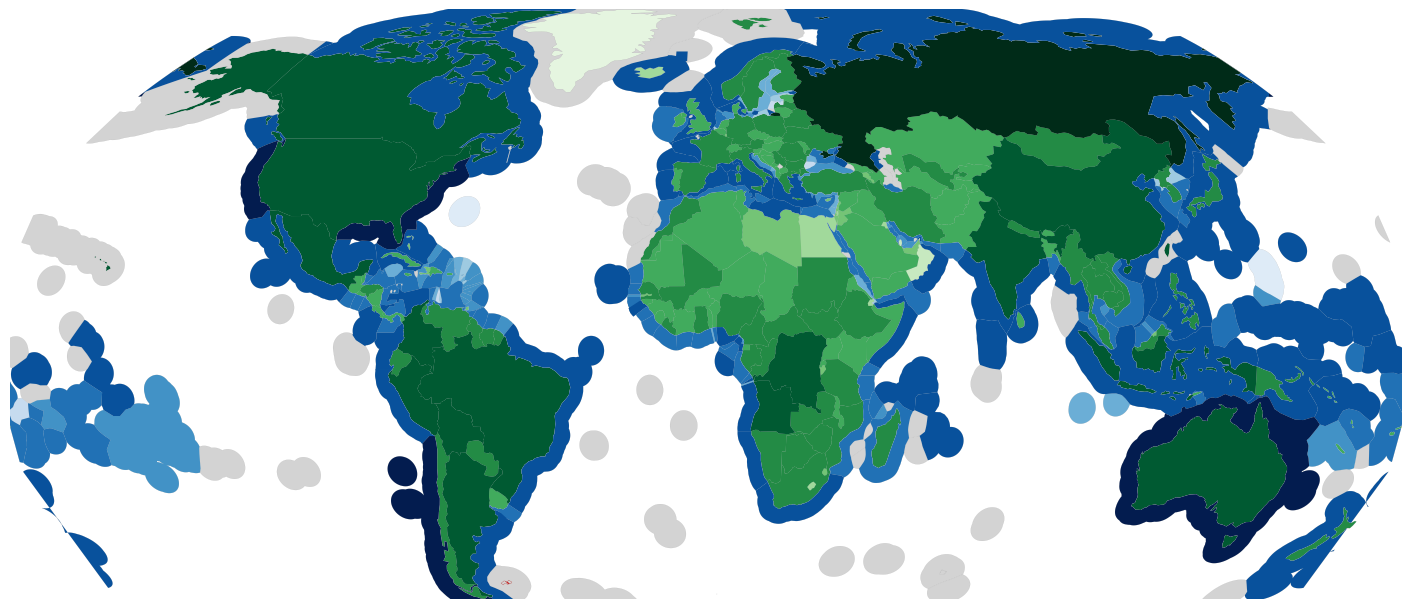

Paper illustration caption:
Paper illustration: Green Carbon Wealth (GCW) is mapped on land and Blue Carbon Wealth (BCW) in the corresponding EEZs. Separate bounded green and blue scales are used. Grey denotes no data; red diagonal hatching denotes a reported zero. Values come from the current 2024 country-account table; missing accounts are not replaced by zero.
Illustration data audit: 228 positive GCW units, 179 positive BCW units, 8 reported GCW zeros, 0 reported BCW zeros, 1 non-positive BCW residuals shown as no data.


In [13]:
# Paper illustration: global GCW and BCW distribution across land and EEZs.
# Selected unnumbered illustration: terrestrial GCW on land and marine BCW in EEZs.
# The map uses Natural Earth 110m boundaries in ESRI:54030.
# Both layers use the current account table loaded above; no values are imputed.
from matplotlib.patches import Patch, Rectangle

accounts_path = TABLES / 'Supplementary_country_level_accounts_2024.csv'
account_map = base[['UNIT_CODE', 'gcw_usd2015_yr_mean', 'bcw_usd2015_yr_mean', 'has_gcw', 'has_bcw']].copy()
account_map['gcw_billion'] = pd.to_numeric(account_map['gcw_usd2015_yr_mean'], errors='coerce') / 1e9
account_map['bcw_billion'] = pd.to_numeric(account_map['bcw_usd2015_yr_mean'], errors='coerce') / 1e9
account_map['gcw_valid'] = account_map['has_gcw'] & account_map['gcw_billion'].gt(0)
account_map['bcw_valid'] = account_map['has_bcw'] & account_map['bcw_billion'].gt(0)
account_map['gcw_zero'] = account_map['has_gcw'] & account_map['gcw_billion'].eq(0)
account_map['bcw_zero'] = account_map['has_bcw'] & account_map['bcw_billion'].eq(0)

bcw_map_path = DATA / 'raw/geospatial/boundaries/ne_110m_admin_0_countries.shp'
if not bcw_map_path.exists():
    raise FileNotFoundError(f'BCW-compatible Natural Earth map not found: {bcw_map_path}')
bcw_world = gpd.read_file(bcw_map_path)
bcw_world['iso3'] = bcw_world['ADM0_A3'].replace(NE_TO_UNIT)
bcw_world = bcw_world.dissolve('iso3', as_index=False)[['iso3', 'geometry']]
bcw_world = bcw_world.loc[bcw_world['iso3'] != 'ATA'].to_crs('ESRI:54030')
bcw_world['geometry'] = bcw_world.geometry.make_valid()
bcw_world_bounds = bcw_world.total_bounds

land = bcw_world.merge(
    account_map[['UNIT_CODE', 'gcw_billion', 'gcw_valid', 'gcw_zero']],
    left_on='iso3', right_on='UNIT_CODE', how='left',
).copy()
land['gcw_valid'] = land['gcw_valid'].fillna(False)
land['gcw_zero'] = land['gcw_zero'].fillna(False)

eez = gpd.read_file(DATA / 'raw/geospatial/boundaries/EEZ_land_union_v4_202410.shp')
if eez.crs is None:
    eez = eez.set_crs('EPSG:4326')
eez = eez.to_crs('ESRI:54030')
eez['geometry'] = eez.geometry.make_valid()
# The BCW polygons are displayed only in the maritime part of each EEZ.
land_union = bcw_world.geometry.make_valid().union_all()
eez['geometry'] = eez.geometry.difference(land_union)
eez = eez.loc[[geom is not None and not geom.is_empty for geom in eez.geometry]].copy()
eez = eez.merge(
    account_map[['UNIT_CODE', 'bcw_billion', 'bcw_valid', 'bcw_zero']],
    left_on='ISO_TER1', right_on='UNIT_CODE', how='left',
).copy()
eez['bcw_valid'] = eez['bcw_valid'].fillna(False)
eez['bcw_zero'] = eez['bcw_zero'].fillna(False)

# Use explicit bounded classes rather than an automatic min-max gradient.
gcw_bounds = [0, 1e-3, 1e-2, 1e-1, 1, 10, 100, 1000, np.inf]
bcw_bounds = [0, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100, np.inf]
green_colors = ['#E5F5E0', '#C7E9C0', '#A1D99B', '#74C476', '#41AB5D', '#238B45', '#005A32', '#002B18']
blue_colors = ['#DEEBF7', '#C6DBEF', '#9ECAE1', '#6BAED6', '#4292C6', '#2171B5', '#08519C', '#031C4F']
land['gcw_class'] = pd.cut(land['gcw_billion'], bins=gcw_bounds, labels=False, include_lowest=True)
eez['bcw_class'] = pd.cut(eez['bcw_billion'], bins=bcw_bounds, labels=False, include_lowest=True)

fig_map, ax_map = plt.subplots(figsize=(14.2, 7.0), facecolor='white')
fig_map.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.99)
ax_map.set_facecolor(MISSING_COLOR)
land.plot(ax=ax_map, color=MISSING_COLOR, edgecolor=EDGE_GREY, linewidth=0.18, zorder=1)
for class_id, color in enumerate(green_colors):
    land.loc[land['gcw_class'].eq(class_id)].plot(ax=ax_map, color=color, edgecolor='none', zorder=2)
land.loc[land['gcw_zero']].plot(ax=ax_map, color=MISSING_COLOR, edgecolor=ZERO_EDGE, linewidth=0.35, hatch=ZERO_HATCH, zorder=3)

# Grey maritime polygons are retained so missing BCW coverage is explicit.
eez.plot(ax=ax_map, color=MISSING_COLOR, edgecolor=EDGE_GREY, linewidth=0.08, zorder=4)
for class_id, color in enumerate(blue_colors):
    eez.loc[eez['bcw_class'].eq(class_id)].plot(ax=ax_map, color=color, edgecolor='none', zorder=5)
if eez['bcw_zero'].any():
    eez.loc[eez['bcw_zero']].plot(ax=ax_map, color=MISSING_COLOR, edgecolor=ZERO_EDGE, linewidth=0.35, hatch=ZERO_HATCH, zorder=6)
ax_map.set_xlim(bcw_world_bounds[0], bcw_world_bounds[2])
ax_map.set_ylim(bcw_world_bounds[1], bcw_world_bounds[3])
ax_map.axis('off')

save(fig_map, "Paper_Illustration")
plt.show()
print("Paper illustration caption:\nPaper illustration: Green Carbon Wealth (GCW) is mapped on land and Blue Carbon Wealth (BCW) in the corresponding EEZs. Separate bounded green and blue scales are used. Grey denotes no data; red diagonal hatching denotes a reported zero. Values come from the current 2024 country-account table; missing accounts are not replaced by zero.")
bcw_nonpositive = account_map['has_bcw'] & account_map['bcw_billion'].le(0) & ~account_map['bcw_zero']
print(f"Illustration data audit: {int(account_map['gcw_valid'].sum())} positive GCW units, {int(account_map['bcw_valid'].sum())} positive BCW units, {int(account_map['gcw_zero'].sum())} reported GCW zeros, {int(account_map['bcw_zero'].sum())} reported BCW zeros, {int(bcw_nonpositive.sum())} non-positive BCW residuals shown as no data.")

In [14]:
# Test candidate: BCW-style geographic map with focused insets.# The BCW paper notebook uses EPSG:4326 for its displayed world maps.# The 110m layer remains the global background; 50m geometry is used only in insets.from matplotlib.patches import Patchfrom mpl_toolkits.axes_grid1.inset_locator import mark_insetMAP_CRS = 'EPSG:4326'EDGE_MAIN = '#4A4A4A'EDGE_EEZ = '#8A8A8A'GREEN_TEST = ['#EDF8E9', '#C7E9C0', '#A1D99B', '#74C476', '#41AB5D', '#238B45', '#006D2C', '#00441B']BLUE_TEST = ['#EFF6FB', '#C6DBEF', '#9ECAE1', '#6BAED6', '#4292C6', '#2171B5', '#08519C', '#08306B']GCW_TEST_BOUNDS = [0, 1e-3, 1e-2, 1e-1, 1, 10, 100, 1000, np.inf]BCW_TEST_BOUNDS = [0, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100, np.inf]def interval_labels(bounds):    labels = []    for lo, hi in zip(bounds[:-1], bounds[1:]):        if lo == 0:            labels.append(f'<{hi:g}')        elif np.isinf(hi):            labels.append(f'>={lo:g}')        else:            labels.append(f'{lo:g}-{hi:g}')    return labelsdef prepare_world(path, iso_column='ADM0_A3'):    frame = gpd.read_file(path)    frame['iso3'] = frame[iso_column].replace(NE_TO_UNIT)    return frame.dissolve('iso3', as_index=False)[['iso3', 'geometry']].to_crs(MAP_CRS)world110_test = prepare_world(DATA / 'raw/geospatial/boundaries/ne_110m_admin_0_countries.shp')world110_test['geometry'] = world110_test.geometry.make_valid()world50_test = prepare_world('/vsizip/' + (DATA / 'raw/geospatial/boundaries/ne_50m_admin_0_countries.zip').as_posix() + '/ne_50m_admin_0_countries.shp')world50_test['geometry'] = world50_test.geometry.make_valid()land_test = world110_test.merge(    account_map[['UNIT_CODE', 'gcw_billion', 'gcw_valid', 'gcw_zero']],    left_on='iso3', right_on='UNIT_CODE', how='left').copy()land_test['gcw_class'] = pd.cut(    land_test['gcw_billion'], bins=GCW_TEST_BOUNDS, labels=False, include_lowest=True)land50_test = world50_test.merge(    account_map[['UNIT_CODE', 'gcw_billion', 'gcw_valid', 'gcw_zero']],    left_on='iso3', right_on='UNIT_CODE', how='left').copy()land50_test['gcw_class'] = pd.cut(    land50_test['gcw_billion'], bins=GCW_TEST_BOUNDS, labels=False, include_lowest=True)eez4326_test = gpd.read_file(DATA / 'raw/geospatial/boundaries/EEZ_land_union_v4_202410.shp')if eez4326_test.crs is None:    eez4326_test = eez4326_test.set_crs(MAP_CRS)else:    eez4326_test = eez4326_test.to_crs(MAP_CRS)eez4326_test['geometry'] = eez4326_test.geometry.make_valid()land_union_test = world110_test.geometry.union_all()eez4326_test['geometry'] = eez4326_test.geometry.difference(land_union_test)eez4326_test = eez4326_test.loc[~eez4326_test.geometry.is_empty].copy()eez4326_test = eez4326_test.merge(    account_map[['UNIT_CODE', 'bcw_billion', 'bcw_valid', 'bcw_zero']],    left_on='ISO_TER1', right_on='UNIT_CODE', how='left').copy()eez4326_test['bcw_class'] = pd.cut(    eez4326_test['bcw_billion'], bins=BCW_TEST_BOUNDS, labels=False, include_lowest=True)fig_test, ax_test = plt.subplots(figsize=(15.5, 8.5), facecolor='white')fig_test.subplots_adjust(left=0.015, right=0.985, top=0.975, bottom=0.245)ax_test.set_facecolor(MISSING_COLOR)land_test.plot(ax=ax_test, color=MISSING_COLOR, edgecolor=EDGE_MAIN, linewidth=0.28, zorder=1)for class_id, color in enumerate(GREEN_TEST):    land_test.loc[land_test['gcw_class'].eq(class_id)].plot(        ax=ax_test, color=color, edgecolor=EDGE_MAIN, linewidth=0.22, zorder=2    )land_test.loc[land_test['gcw_zero'].fillna(False)].plot(    ax=ax_test, color=MISSING_COLOR, edgecolor=ZERO_EDGE, linewidth=0.55, hatch=ZERO_HATCH, zorder=3)eez4326_test.plot(ax=ax_test, color=MISSING_COLOR, edgecolor=EDGE_EEZ, linewidth=0.10, zorder=4)for class_id, color in enumerate(BLUE_TEST):    eez4326_test.loc[eez4326_test['bcw_class'].eq(class_id)].plot(        ax=ax_test, color=color, edgecolor=EDGE_EEZ, linewidth=0.10, zorder=5    )if eez4326_test['bcw_zero'].fillna(False).any():    eez4326_test.loc[eez4326_test['bcw_zero'].fillna(False)].plot(        ax=ax_test, color=MISSING_COLOR, edgecolor=ZERO_EDGE, linewidth=0.55, hatch=ZERO_HATCH, zorder=6    )ax_test.set_xlim(-180, 180)ax_test.set_ylim(-60, 85)ax_test.axis('off')def draw_focus(parent, bounds, title):    x0, x1, y0, y1 = bounds    focus = parent.inset_axes([0.0, 0.0, 1.0, 1.0])    focus.set_facecolor(MISSING_COLOR)    land50_test.plot(ax=focus, color=MISSING_COLOR, edgecolor=EDGE_MAIN, linewidth=0.65, zorder=1)    for class_id, color in enumerate(GREEN_TEST):        land50_test.loc[land50_test['gcw_class'].eq(class_id)].plot(            ax=focus, color=color, edgecolor=EDGE_MAIN, linewidth=0.50, zorder=2        )    land50_test.loc[land50_test['gcw_zero'].fillna(False)].plot(        ax=focus, color=MISSING_COLOR, edgecolor=ZERO_EDGE, linewidth=0.9, hatch=ZERO_HATCH, zorder=3    )    eez4326_test.plot(ax=focus, color=MISSING_COLOR, edgecolor=EDGE_EEZ, linewidth=0.22, zorder=4)    for class_id, color in enumerate(BLUE_TEST):        eez4326_test.loc[eez4326_test['bcw_class'].eq(class_id)].plot(            ax=focus, color=color, edgecolor=EDGE_EEZ, linewidth=0.22, zorder=5        )    if eez4326_test['bcw_zero'].fillna(False).any():        eez4326_test.loc[eez4326_test['bcw_zero'].fillna(False)].plot(            ax=focus, color=MISSING_COLOR, edgecolor=ZERO_EDGE, linewidth=0.9, hatch=ZERO_HATCH, zorder=6        )    focus.set_xlim(x0, x1)    focus.set_ylim(y0, y1)    focus.axis('off')    focus.set_title(title, fontsize=7.5, pad=2, color=TEXT)    return focuscaribbean = ax_test.inset_axes([0.015, 0.635, 0.235, 0.285])europe = ax_test.inset_axes([0.750, 0.635, 0.235, 0.285])pacific = ax_test.inset_axes([0.385, 0.635, 0.230, 0.285])def draw_focus_on_axis(focus, bounds, title):    x0, x1, y0, y1 = bounds    focus.set_facecolor(MISSING_COLOR)    land50_test.plot(ax=focus, color=MISSING_COLOR, edgecolor=EDGE_MAIN, linewidth=0.65, zorder=1)    for class_id, color in enumerate(GREEN_TEST):        land50_test.loc[land50_test['gcw_class'].eq(class_id)].plot(            ax=focus, color=color, edgecolor=EDGE_MAIN, linewidth=0.50, zorder=2        )    land50_test.loc[land50_test['gcw_zero'].fillna(False)].plot(        ax=focus, color=MISSING_COLOR, edgecolor=ZERO_EDGE, linewidth=0.9, hatch=ZERO_HATCH, zorder=3    )    eez4326_test.plot(ax=focus, color=MISSING_COLOR, edgecolor=EDGE_EEZ, linewidth=0.22, zorder=4)    for class_id, color in enumerate(BLUE_TEST):        eez4326_test.loc[eez4326_test['bcw_class'].eq(class_id)].plot(            ax=focus, color=color, edgecolor=EDGE_EEZ, linewidth=0.22, zorder=5        )    focus.set_xlim(x0, x1)    focus.set_ylim(y0, y1)    focus.axis('off')    focus.set_title(title, fontsize=7.5, pad=2, color=TEXT)draw_focus_on_axis(caribbean, (-92, -55, 5, 32), 'Caribbean detail')draw_focus_on_axis(europe, (-8, 22, 30, 50), 'European microstates')draw_focus_on_axis(pacific, (145, 180, -15, 15), 'Pacific detail')for focus, loc1, loc2 in [(caribbean, 2, 4), (europe, 1, 3), (pacific, 2, 4)]:    mark_inset(ax_test, focus, loc1=loc1, loc2=loc2, fc='none', ec=EDGE_MAIN, lw=0.75)gcw_labels_test = interval_labels(GCW_TEST_BOUNDS)bcw_labels_test = interval_labels(BCW_TEST_BOUNDS)gcw_handles = [Patch(facecolor=c, edgecolor=EDGE_MAIN, linewidth=0.3, label=l) for c, l in zip(GREEN_TEST, gcw_labels_test)]bcw_handles = [Patch(facecolor=c, edgecolor=EDGE_EEZ, linewidth=0.3, label=l) for c, l in zip(BLUE_TEST, bcw_labels_test)]fig_test.legend(    handles=gcw_handles, title='GCW (billion US$2015 per year)',    loc='lower center', bbox_to_anchor=(0.50, 0.145), ncol=8, frameon=False,    fontsize=6.3, title_fontsize=7.4, handlelength=1.0, columnspacing=0.55)fig_test.legend(    handles=bcw_handles, title='BCW (billion US$2015 per year)',    loc='lower center', bbox_to_anchor=(0.50, 0.082), ncol=8, frameon=False,    fontsize=6.3, title_fontsize=7.4, handlelength=1.0, columnspacing=0.55)fig_test.legend(    handles=[        Patch(facecolor=MISSING_COLOR, edgecolor=EDGE_MAIN, label='No data'),        Patch(facecolor=MISSING_COLOR, edgecolor=ZERO_EDGE, hatch=ZERO_HATCH, label='Zero reported'),    ],    loc='lower right', bbox_to_anchor=(0.985, 0.020), ncol=2, frameon=True,    framealpha=0.92, edgecolor='#B0B0B0', fontsize=7.2, handlelength=1.2, columnspacing=0.8)zero_codes = sorted(account_map.loc[account_map['gcw_zero'], 'UNIT_CODE'].dropna().astype(str))visible_zero_codes = sorted(set(zero_codes).intersection(set(world50_test['iso3'].dropna())))print('Illustration test caption:\nIllustration test: GCW is mapped on land and BCW in the corresponding EEZs. The display uses EPSG:4326, matching the BCW paper notebook, rather than a curved Robinson projection. The 110m layer is used globally and 50m boundaries are used only in the three focus insets. Dark borders separate countries and EEZs. Grey denotes no data; red diagonal hatching denotes a reported zero.')print(f'Zero-reported GCW units in the account table: {len(zero_codes)} ({", ".join(zero_codes)}). Visible in the 50m inset layer: {len(visible_zero_codes)} ({", ".join(visible_zero_codes)}).')test_path = ROOT / 'tmp' / 'Candidate_Illustration_GCW_BCW_land_EEZ_insets_test.png'test_path.parent.mkdir(parents=True, exist_ok=True)fig_test.savefig(test_path, dpi=180, bbox_inches='tight', facecolor=fig_test.get_facecolor())plt.show()

Figure 1 caption:
Fig. 1: Global distribution of green and blue carbon wealth. GCW is mapped on land and BCW in the corresponding EEZs (EPSG:4326). Land boundaries use Natural Earth 10m map units; numbered frames on the global panel mark the three focus panels above it. Separate bounded green and blue scales are used. Grey denotes no data; red hatching with a red outline denotes a reported zero. Labelled territories in panels 2 and 3 are reported zeros too small to read at global scale.
Zero-reported GCW units: 8 (FLK, GIB, KIR, MCO, NRU, SJM, TKL, VAT). Drawn with their own 10m polygon: 8 (FLK, GIB, KIR, MCO, NRU, SJM, TKL, VAT).


[saved] Figure1.png


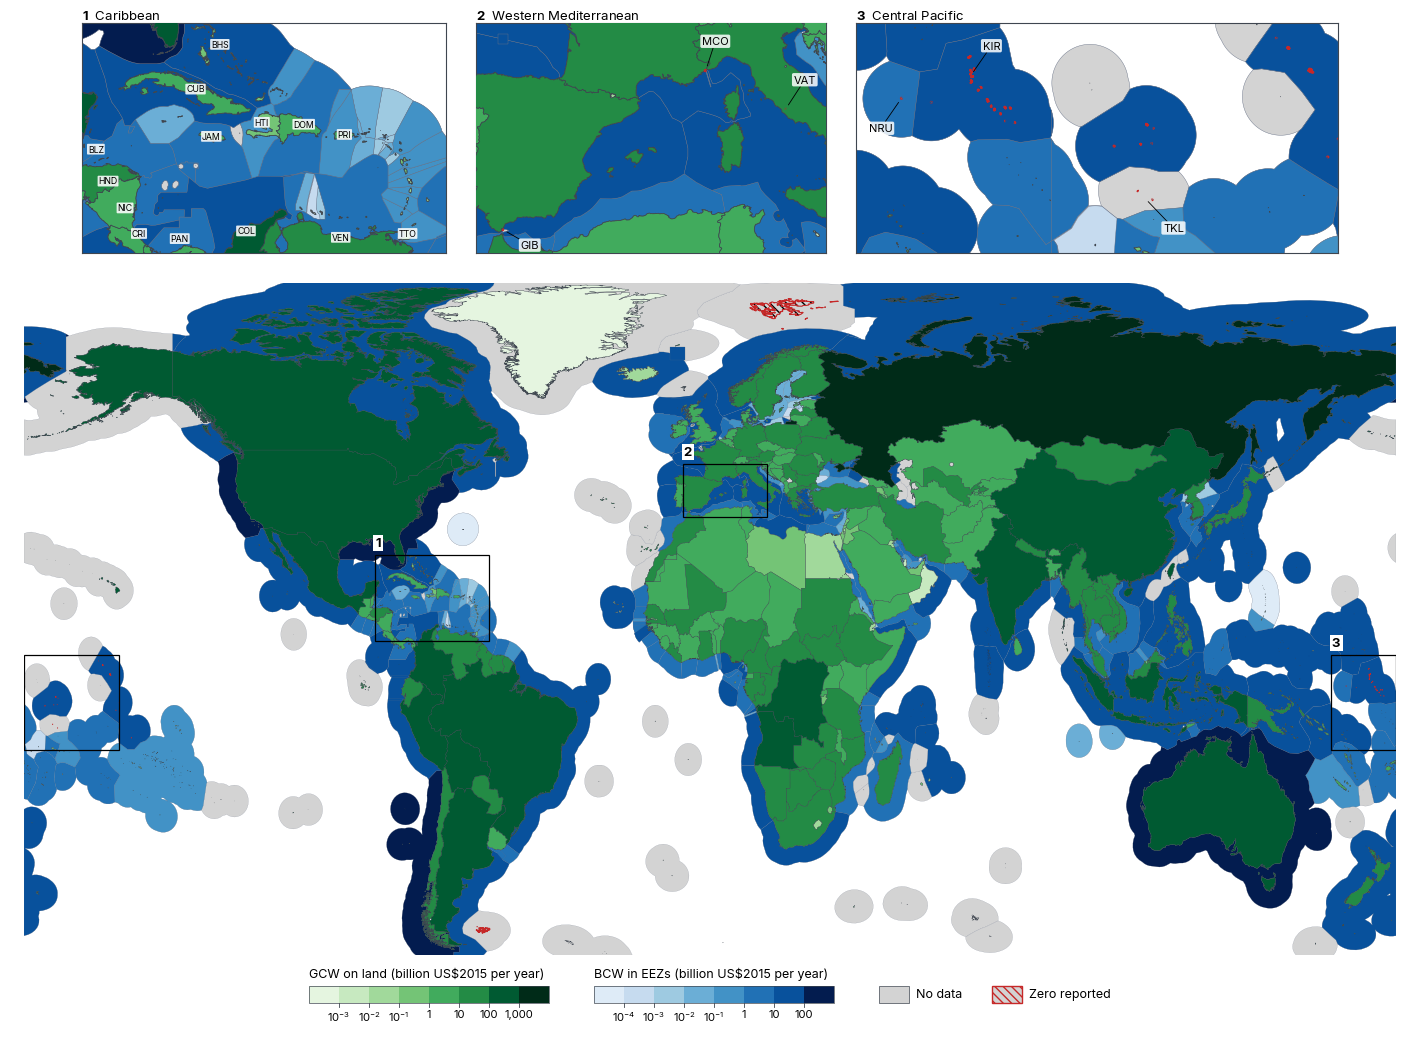

In [15]:
# Figure 1: Global distribution of green and blue carbon wealth.
# Selected manuscript map: flat BCW-style global map with focused insets and compact legends.
# Layout: three numbered focus panels on top, the global map below them (never
# overlapping), then one compact legend row. Land uses Natural Earth 10m map units so
# small territories (GIB, TKL, SJM, French overseas departments) keep their own
# polygon and reported zeros follow the real coastline instead of display markers.
from matplotlib.patches import Patch
from shapely import affinity
from shapely.geometry import box

MAP_CRS_TEST = 'EPSG:4326'
EDGE_MAIN_TEST = '#3F4650'
EDGE_EEZ_TEST = '#667085'
GREEN_TEST = ['#E5F5E0', '#C7E9C0', '#A1D99B', '#74C476', '#41AB5D', '#238B45', '#005A32', '#002B18']
BLUE_TEST = ['#DEEBF7', '#C6DBEF', '#9ECAE1', '#6BAED6', '#4292C6', '#2171B5', '#08519C', '#031C4F']
MAIN_EXTENT_TEST = (-180, 180, -57, 84)
# Vertical stretch of the global panel relative to plate carree (1.0); gives the map more height.
MAIN_ASPECT_TEST = 1.25

# 10m map units split overseas departments and dependencies that 50m folds into the
# sovereign state. Codes resolve as GU_A3, then ISO_A3, then ADM0_A3 with NE_TO_UNIT.
units_test = set(account_map['UNIT_CODE'].dropna())
world10_test = gpd.read_file('/vsizip/' + (DATA / 'raw/geospatial/boundaries/ne_10m_admin_0_map_units.zip').as_posix()
                             + '/ne_10m_admin_0_map_units.shp')
world10_test['iso3'] = [
    gu if gu in units_test else iso if iso in units_test else NE_TO_UNIT.get(adm, adm)
    for gu, iso, adm in zip(world10_test['GU_A3'], world10_test['ISO_A3'], world10_test['ADM0_A3'])
]
world10_test = world10_test.dissolve('iso3', as_index=False)[['iso3', 'geometry']]
world10_test = world10_test.loc[world10_test['iso3'] != 'ATA'].to_crs(MAP_CRS_TEST)
world10_test['geometry'] = world10_test.geometry.make_valid()

land_hi_test = world10_test.merge(
    account_map[['UNIT_CODE', 'gcw_billion', 'gcw_valid', 'gcw_zero']],
    left_on='iso3', right_on='UNIT_CODE', how='left',
).copy()
land_hi_test['gcw_zero'] = land_hi_test['gcw_zero'].fillna(False).astype(bool)
land_hi_test['gcw_class'] = pd.cut(land_hi_test['gcw_billion'], bins=gcw_bounds, labels=False, include_lowest=True)
# The global panel uses a lightly simplified copy; focus panels keep full 10m detail.
land_lo_test = land_hi_test.copy()
land_lo_test['geometry'] = land_lo_test.geometry.simplify(0.02, preserve_topology=True)

# EEZ land-union polygons are drawn below land, so no land subtraction is needed.
eez_test = gpd.read_file(DATA / 'raw/geospatial/boundaries/EEZ_land_union_v4_202410.shp')
eez_test = eez_test.set_crs(MAP_CRS_TEST) if eez_test.crs is None else eez_test.to_crs(MAP_CRS_TEST)
eez_test['geometry'] = eez_test.geometry.make_valid()
eez_test = eez_test.merge(
    account_map[['UNIT_CODE', 'bcw_billion', 'bcw_valid', 'bcw_zero']],
    left_on='ISO_TER1', right_on='UNIT_CODE', how='left',
).copy()
eez_test['bcw_zero'] = eez_test['bcw_zero'].fillna(False).astype(bool)
eez_test['bcw_class'] = pd.cut(eez_test['bcw_billion'], bins=bcw_bounds, labels=False, include_lowest=True)
eez_lo_test = eez_test.copy()
eez_lo_test['geometry'] = eez_lo_test.geometry.simplify(0.03, preserve_topology=True)

missing_units_test = sorted(set(account_map.loc[account_map['has_gcw'], 'UNIT_CODE']) - set(world10_test['iso3']))
if missing_units_test:
    print(f'GCW units without a 10m land polygon: {missing_units_test}')


def wrap_east_test(frame, extent):
    """Clip a frame to an extent given in 0-360 longitudes (crossing the antimeridian)."""
    x0, x1, y0, y1 = extent
    parts = []
    for lo, hi, shift in ((x0, 180, 0), (-180, x1 - 360, 360)):
        clip = frame.loc[frame.intersects(box(lo, y0, hi, y1))].copy()
        clip['geometry'] = [affinity.translate(g.intersection(box(lo, y0, hi, y1)), xoff=shift) for g in clip.geometry]
        parts.append(clip)
    out = pd.concat(parts, ignore_index=True)
    return gpd.GeoDataFrame(out[~out.geometry.is_empty], geometry='geometry', crs=frame.crs)


def local_aspect_test(extent):
    return 1 / np.cos(np.radians((extent[2] + extent[3]) / 2))


def draw_test_map(ax, land_frame, eez_frame, extent, inset=False):
    x0, x1, y0, y1 = extent
    lw_land, lw_eez, lw_zero = (0.55, 0.30, 1.8) if inset else (0.22, 0.10, 0.75)
    eez_frame.plot(ax=ax, color=MISSING_COLOR, edgecolor=EDGE_EEZ_TEST, linewidth=lw_eez, aspect=None, zorder=1)
    for class_id, color in enumerate(BLUE_TEST):
        subset = eez_frame.loc[eez_frame['bcw_class'].eq(class_id)]
        if not subset.empty:
            subset.plot(ax=ax, color=color, edgecolor=EDGE_EEZ_TEST, linewidth=lw_eez, aspect=None, zorder=2)
    zero_eez = eez_frame.loc[eez_frame['bcw_zero']]
    if not zero_eez.empty:
        zero_eez.plot(ax=ax, color=MISSING_COLOR, edgecolor=ZERO_EDGE, linewidth=lw_zero, hatch=ZERO_HATCH, aspect=None, zorder=3)
    land_frame.plot(ax=ax, color=MISSING_COLOR, edgecolor=EDGE_MAIN_TEST, linewidth=lw_land, aspect=None, zorder=4)
    for class_id, color in enumerate(GREEN_TEST):
        subset = land_frame.loc[land_frame['gcw_class'].eq(class_id) & ~land_frame['gcw_zero']]
        if not subset.empty:
            subset.plot(ax=ax, color=color, edgecolor=EDGE_MAIN_TEST, linewidth=lw_land, aspect=None, zorder=5)
    zero_land = land_frame.loc[land_frame['gcw_zero']]
    if not zero_land.empty:
        zero_land.plot(ax=ax, color=MISSING_COLOR, edgecolor='none', hatch=ZERO_HATCH, aspect=None, zorder=6)
        # The red outline follows the coastline; its stroke width keeps sub-pixel
        # territories (Monaco, Vatican, Gibraltar, Tokelau atolls) visible.
        zero_land.boundary.plot(ax=ax, color=ZERO_EDGE, linewidth=lw_zero, aspect=None, zorder=7)
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    # Focus panels correct for latitude so local shapes read true.
    ax.set_aspect(local_aspect_test(extent) if inset else MAIN_ASPECT_TEST, adjustable='box')
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(inset)
        spine.set_edgecolor(EDGE_MAIN_TEST)
        spine.set_linewidth(0.8)
    ax.set_facecolor('white')


# Focus panels are chosen by information density: the Caribbean holds the densest
# cluster of small accounted units and EEZs, the western Mediterranean holds three
# reported-zero microstates (GIB, MCO, VAT), and the central Pacific holds the other
# small-island zeros (NRU, KIR, TKL) across the antimeridian. Svalbard and the Falklands
# are large enough to read on the global panel.
# (number, title, extent, crosses_antimeridian, zero-label offsets in degrees)
focus_specs_test = [
    (1, 'Caribbean', (-88, -58, 9, 27), False, {}),
    (2, 'Western Mediterranean', (-7, 15, 35, 46), False,
     {'GIB': (1.7, -0.75), 'MCO': (0.6, 1.4), 'VAT': (1.2, 1.4)}),
    (3, 'Central Pacific', (163, 205, -14, 6), True,
     {'NRU': (-1.8, -2.6), 'KIR': (1.8, 2.6), 'TKL': (2.5, -2.6)}),
]
zero_anchor_test = {'GIB': (-5.35, 36.14), 'MCO': (7.42, 43.74), 'VAT': (12.45, 41.90),
                    'NRU': (166.93, -0.53), 'KIR': (172.98, 1.45), 'TKL': (188.15, -9.20)}
caribbean_labels_test = {
    'BLZ': (-86.85, 17.15), 'HND': (-85.85, 14.65), 'NIC': (-84.45, 12.55),
    'CRI': (-83.30, 10.55), 'PAN': (-79.95, 10.15), 'CUB': (-78.65, 21.85),
    'BHS': (-76.65, 25.35), 'JAM': (-77.35, 18.15), 'HTI': (-73.20, 19.25),
    'DOM': (-69.75, 19.10), 'PRI': (-66.40, 18.30), 'TTO': (-61.20, 10.55),
    'COL': (-74.50, 10.75), 'VEN': (-66.70, 10.25),
}

# Vertical layout in inches, top to bottom: focus panels, global map, one legend row.
fig_w, margin_in = 14.0, 0.14
focus_h_in, title_in, gap_in = 2.3, 0.30, 0.30
map_w_in = fig_w - 2 * margin_in
map_h_in = map_w_in * (MAIN_EXTENT_TEST[3] - MAIN_EXTENT_TEST[2]) / (MAIN_EXTENT_TEST[1] - MAIN_EXTENT_TEST[0]) * MAIN_ASPECT_TEST
legend_h_in = 0.62
fig_h = margin_in + title_in + focus_h_in + gap_in + map_h_in + 0.10 + legend_h_in + margin_in
fig_test_v2 = plt.figure(figsize=(fig_w, fig_h), facecolor='white')


def axes_in(x_in, y_top_in, w_in, h_in):
    """Add axes from inch coordinates measured from the top-left corner."""
    return fig_test_v2.add_axes([x_in / fig_w, 1 - (y_top_in + h_in) / fig_h, w_in / fig_w, h_in / fig_h])


focus_top_in = margin_in + title_in
map_top_in = focus_top_in + focus_h_in + gap_in
ax_test_v2 = axes_in(margin_in, map_top_in, map_w_in, map_h_in)
draw_test_map(ax_test_v2, land_lo_test, eez_lo_test, MAIN_EXTENT_TEST)

# Focus panels share one height; widths follow each extent's aspect ratio.
widths_in = [focus_h_in * (e[1] - e[0]) / ((e[3] - e[2]) * local_aspect_test(e)) for _, _, e, _, _ in focus_specs_test]
x_in = (fig_w - sum(widths_in) - gap_in * (len(widths_in) - 1)) / 2
for (num, title, extent, wraps, offsets), width_in in zip(focus_specs_test, widths_in):
    inset_ax = axes_in(x_in, focus_top_in, width_in, focus_h_in)
    x_in += width_in + gap_in
    land_f = wrap_east_test(land_hi_test, extent) if wraps else land_hi_test.cx[extent[0]:extent[1], extent[2]:extent[3]]
    eez_f = wrap_east_test(eez_test, extent) if wraps else eez_test.cx[extent[0]:extent[1], extent[2]:extent[3]]
    draw_test_map(inset_ax, land_f, eez_f, extent, inset=True)
    inset_ax.set_title(f'${BOLD}{{{num}}}$  {title}', loc='left', fontsize=9.5, pad=3, color=TEXT)
    for code, (dx, dy) in offsets.items():
        lon, lat = zero_anchor_test[code]
        inset_ax.annotate(code, xy=(lon, lat), xytext=(lon + dx, lat + dy), fontsize=8, color=TEXT,
                          ha='center', va='center', zorder=9,
                          bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85),
                          arrowprops=dict(arrowstyle='-', color=TEXT, lw=0.6, shrinkA=0, shrinkB=3.5))
    if num == 1:
        for code, (lon, lat) in caribbean_labels_test.items():
            inset_ax.text(lon, lat, code, ha='center', va='center', fontsize=6.3, color=TEXT, zorder=8,
                          bbox=dict(boxstyle='round,pad=0.10', fc='white', ec='none', alpha=0.88))
    # Matching numbered frames on the global panel; the Pacific frame is split at 180 degrees.
    x0, x1, y0, y1 = extent
    spans = [(x0, 180), (-180, x1 - 360)] if wraps else [(x0, x1)]
    for lo, hi in spans:
        ax_test_v2.add_patch(Rectangle((lo, y0), hi - lo, y1 - y0, fill=False, ec='black', lw=0.9, zorder=10))
    ax_test_v2.text(x0, y1 + 1.2, f'${BOLD}{{{num}}}$', fontsize=9.5, ha='left', va='bottom', zorder=10,
                    bbox=dict(boxstyle='square,pad=0.12', fc='white', ec='none'))

# One legend row in inch units: GCW bar, BCW bar, then No data and Zero reported swatches
# drawn with exactly the size of one colour class.
box_w_in, box_h_in, box_y_in = 0.30, 0.17, 0.24
legend_ax = axes_in(0, fig_h - margin_in - legend_h_in, fig_w, legend_h_in)
legend_ax.set_xlim(0, fig_w)
legend_ax.set_ylim(0, legend_h_in)
legend_ax.axis('off')
renderer = fig_test_v2.canvas.get_renderer()


def text_width_in(text):
    return text.get_window_extent(renderer).width / fig_test_v2.dpi


def break_label(value):
    # Powers of ten keep sub-unit breaks as narrow as the class boxes.
    return f'{value:,g}' if value >= 1 else f'$10^{{{int(round(np.log10(value)))}}}$'


def add_class_bar(x0, colors, breaks, title):
    """One continuous bar per account, labels at class breaks; end classes are open."""
    for i, color in enumerate(colors):
        legend_ax.add_patch(Rectangle((x0 + i * box_w_in, box_y_in), box_w_in, box_h_in, facecolor=color, edgecolor='none'))
    legend_ax.add_patch(Rectangle((x0, box_y_in), len(colors) * box_w_in, box_h_in, fill=False,
                                  edgecolor=EDGE_MAIN_TEST, lw=0.5))
    for i, value in enumerate(breaks, start=1):
        xb = x0 + i * box_w_in
        legend_ax.plot([xb, xb], [box_y_in - 0.04, box_y_in], color=EDGE_MAIN_TEST, lw=0.6)
        legend_ax.text(xb, box_y_in - 0.06, break_label(value), ha='center', va='top', fontsize=8, color=TEXT)
    title_text = legend_ax.text(x0, box_y_in + box_h_in + 0.06, title, ha='left', va='bottom', fontsize=9, color=TEXT)
    # The next group starts after the bar or its title, whichever is wider.
    return x0 + max(len(colors) * box_w_in, text_width_in(title_text))


def add_status_box(x0, label, **style):
    legend_ax.add_patch(Rectangle((x0, box_y_in), box_w_in, box_h_in, facecolor=MISSING_COLOR, **style))
    text = legend_ax.text(x0 + box_w_in + 0.07, box_y_in + box_h_in / 2, label, ha='left', va='center',
                          fontsize=9, color=TEXT)
    return x0 + box_w_in + 0.07 + text_width_in(text)


# Lay the row out once from x=0, then shift every artist so the row is centred.
group_gap_in = 0.45
x_end = add_class_bar(0, GREEN_TEST, gcw_bounds[1:-1], 'GCW on land (billion US$2015 per year)')
x_end = add_class_bar(x_end + group_gap_in, BLUE_TEST, bcw_bounds[1:-1], 'BCW in EEZs (billion US$2015 per year)')
x_end = add_status_box(x_end + group_gap_in, 'No data', edgecolor=EDGE_MAIN_TEST, linewidth=0.5)
x_end = add_status_box(x_end + 0.30, 'Zero reported', edgecolor=ZERO_EDGE, hatch=ZERO_HATCH, linewidth=1.0)
legend_ax.set_xlim(-(fig_w - x_end) / 2, fig_w - (fig_w - x_end) / 2)

zero_codes_test = sorted(account_map.loc[account_map['gcw_zero'], 'UNIT_CODE'].dropna().astype(str))
drawn_zero_test = sorted(set(zero_codes_test) & set(land_hi_test.loc[land_hi_test['gcw_zero'], 'iso3']))
print('Figure 1 caption:')
print('Fig. 1: Global distribution of green and blue carbon wealth. GCW is mapped on land and BCW in the corresponding EEZs (EPSG:4326). '
      'Land boundaries use Natural Earth 10m map units; numbered frames on the global panel mark the three '
      'focus panels above it. Separate bounded green and blue scales are used. Grey denotes no data; red hatching with a red outline denotes a reported zero. '
      'Labelled territories in panels 2 and 3 are reported zeros too small to read at global scale.')
print(f'Zero-reported GCW units: {len(zero_codes_test)} ({", ".join(zero_codes_test)}). '
      f'Drawn with their own 10m polygon: {len(drawn_zero_test)} ({", ".join(drawn_zero_test)}).')
save(fig_test_v2, "Figure1")
plt.show()